# Baseline vs Breaks-Only Comparison

Compares results from:
- **Baseline** (SM_batch.jl): BEVs can charge anywhere
- **Breaks-Only** (SM_batch_breaks_only.jl): Charging only at mandatory breaks

Analyzes:
1. BEV fleet development comparison
2. Charging demand by latitude

In [53]:
import os
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from collections import defaultdict
from scipy.ndimage import gaussian_filter1d
import warnings
warnings.filterwarnings('ignore')

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (14, 6)

print('Libraries loaded')

Libraries loaded


In [54]:
# Configuration
BASE_DIR = os.getcwd()
RESULTS_DIR = os.path.join(BASE_DIR, 'results', 'breaks_comparison_full')

# 4 GENeSYS scenarios - each has with_breaks and without_breaks variant
SCENARIOS = ['go_res', 'necp', 'repower', 'trinity']

SCENARIO_LABELS = {
    'go_res': 'Go RES (EUR500/tCO2)',
    'necp': 'NECP (EUR250/tCO2)',
    'repower': 'REPower (EUR350/tCO2)',
    'trinity': 'Trinity (EUR180/tCO2)'
}

SCENARIO_COLORS = {
    'go_res': '#1f77b4',    # blue
    'necp': '#2ca02c',      # green
    'repower': '#ff7f0e',   # orange
    'trinity': '#d62728'    # red
}

# Carbon prices in 2040 for reference
CARBON_PRICES_2040 = {
    'go_res': 500,
    'necp': 250,
    'repower': 350,
    'trinity': 180
}

def get_baseline_path(scenario):
    """Get path to without_breaks (charging anywhere) results"""
    return os.path.join(RESULTS_DIR, f'{scenario}_without_breaks')

def get_breaks_path(scenario):
    """Get path to with_breaks (charging at breaks only) results"""
    return os.path.join(RESULTS_DIR, f'{scenario}_with_breaks')

print(f'Results directory: {RESULTS_DIR}')
print(f'Scenarios: {SCENARIOS}')
print()
for sc in SCENARIOS:
    print(f'{SCENARIO_LABELS[sc]}:')
    print(f'  Baseline (anywhere): {get_baseline_path(sc)}')
    print(f'  Breaks-only: {get_breaks_path(sc)}')


Results directory: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\breaks_comparison_full
Scenarios: ['go_res', 'necp', 'repower', 'trinity']

Go RES (EUR500/tCO2):
  Baseline (anywhere): c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\breaks_comparison_full\go_res_without_breaks
  Breaks-only: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\breaks_comparison_full\go_res_with_breaks
NECP (EUR250/tCO2):
  Baseline (anywhere): c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\breaks_comparison_full\necp_without_breaks
  Breaks-only: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\breaks_comparison

In [55]:
# Helper functions
def get_latest_file(folder, pattern):
    """Get the most recent file matching a pattern."""
    files = glob(os.path.join(folder, f'*{pattern}'))
    if not files:
        return None
    return max(files, key=os.path.getmtime)

def extract_fleet_by_year(h_dict):
    """Extract fleet by year and technology from h_dict.
    
    Key structure: (year, odpair_id, tv_id, generation)
    tv_id: 0 = ICEV, 1 = BEV (or odd = BEV, even = ICEV)
    """
    fleet_by_year = defaultdict(lambda: {'ICEV': 0, 'BEV': 0})
    
    for key_str, value in h_dict.items():
        try:
            # Parse tuple key from string
            key = eval(key_str) if isinstance(key_str, str) else key_str
            year = key[0]
            tv_id = key[2]
            
            # Convert value to float
            val = float(value) if isinstance(value, str) else value
            
            # tv_id: 0 = ICEV, 1 = BEV (odd = BEV, even = ICEV)
            tech_name = 'BEV' if tv_id % 2 == 1 else 'ICEV'
            fleet_by_year[year][tech_name] += val
        except Exception as e:
            continue
    
    return fleet_by_year

print('Helper functions defined')


Helper functions defined


## Load Data

In [56]:
# Load fleet data for all scenarios
baseline_fleet = {}
breaks_fleet = {}

for scenario in SCENARIOS:
    print(f'Loading {SCENARIO_LABELS[scenario]}...')
    
    # Baseline
    baseline_path = get_baseline_path(scenario)
    h_file = get_latest_file(baseline_path, '_h_dict.yaml')
    if h_file:
        with open(h_file, 'r') as f:
            h_dict = yaml.safe_load(f)
        baseline_fleet[scenario] = extract_fleet_by_year(h_dict)
        print(f'  Baseline: {len(h_dict)} entries')
    else:
        print(f'  Baseline: NOT FOUND')
    
    # Breaks only
    breaks_path = get_breaks_path(scenario)
    h_file = get_latest_file(breaks_path, '_h_dict.yaml')
    if h_file:
        with open(h_file, 'r') as f:
            h_dict = yaml.safe_load(f)
        breaks_fleet[scenario] = extract_fleet_by_year(h_dict)
        print(f'  Breaks-only: {len(h_dict)} entries')
    else:
        print(f'  Breaks-only: NOT FOUND')

print('\nData loading complete!')

Loading Go RES (EUR500/tCO2)...
  Baseline: 107015 entries
  Breaks-only: 103163 entries
Loading NECP (EUR250/tCO2)...
  Baseline: 107015 entries
  Breaks-only: 103170 entries
Loading REPower (EUR350/tCO2)...
  Baseline: 107015 entries
  Breaks-only: 103179 entries
Loading Trinity (EUR180/tCO2)...
  Baseline: 107015 entries
  Breaks-only: 103179 entries

Data loading complete!


## Fleet Summary Table

In [57]:
# Create summary table
summary_data = []
years_summary = [2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]

for scenario in SCENARIOS:
    for year in years_summary:
        bev_base = baseline_fleet.get(scenario, {}).get(year, {}).get('BEV', 0)
        bev_breaks = breaks_fleet.get(scenario, {}).get(year, {}).get('BEV', 0)
        
        icev_base = baseline_fleet.get(scenario, {}).get(year, {}).get('ICEV', 0)
        icev_breaks = breaks_fleet.get(scenario, {}).get(year, {}).get('ICEV', 0)
        
        total_base = bev_base + icev_base
        total_breaks = bev_breaks + icev_breaks
        
        share_base = (bev_base / total_base * 100) if total_base > 0 else 0
        share_breaks = (bev_breaks / total_breaks * 100) if total_breaks > 0 else 0
        
        delta_abs = bev_breaks - bev_base
        delta_pct = ((bev_breaks - bev_base) / bev_base * 100) if bev_base > 0 else 0
        
        summary_data.append({
            'Scenario': SCENARIO_LABELS[scenario],
            'Year': year,
            'BEV Baseline': bev_base,
            'BEV Breaks': bev_breaks,
            'Delta (vehicles)': delta_abs,
            'Delta (%)': delta_pct,
            'Share Baseline (%)': share_base,
            'Share Breaks (%)': share_breaks
        })

summary_df = pd.DataFrame(summary_data)

# Display 2040 summary
print('='*80)
print('BEV FLEET COMPARISON - 2040')
print('='*80)
display(summary_df[summary_df['Year'] == 2040][['Scenario', 'BEV Baseline', 'BEV Breaks', 'Delta (%)', 'Share Baseline (%)', 'Share Breaks (%)']])

BEV FLEET COMPARISON - 2040


,Scenario,BEV Baseline,BEV Breaks,Delta (%),Share Baseline (%),Share Breaks (%)
3,Go RES (EUR500/tCO2),6496.335448,6533.166377,0.566949,43.826028,44.062674
12,NECP (EUR250/tCO2),6478.887614,6490.349639,0.176913,43.713878,43.787529
21,REPower (EUR350/tCO2),6482.932495,6491.016653,0.124699,43.739878,43.791818
30,Trinity (EUR180/tCO2),6486.780967,6490.819574,0.062259,43.764607,43.790547


## Figure 1: BEV Fleet Development

Saved: figures/bev_fleet_baseline_vs_breaks.pdf


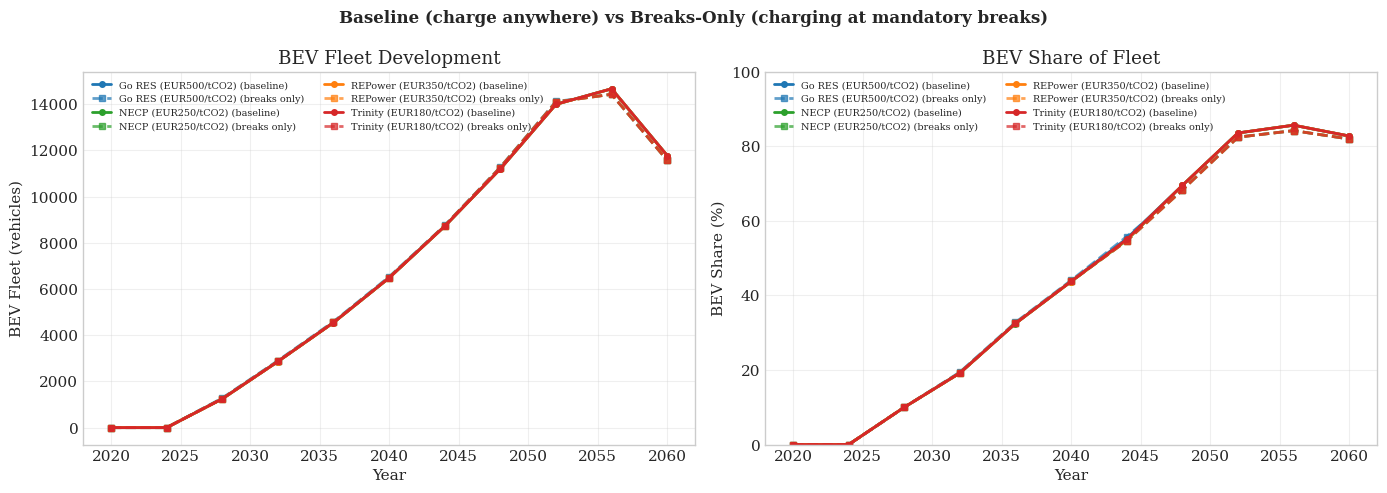

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
years = [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]

# Plot 1: Absolute BEV numbers
ax1 = axes[0]
for scenario in SCENARIOS:
    if scenario in baseline_fleet:
        bev_baseline = [baseline_fleet[scenario][y]['BEV'] for y in years]
        ax1.plot(years, bev_baseline, 'o-', label=f'{SCENARIO_LABELS[scenario]} (baseline)',
                color=SCENARIO_COLORS[scenario], linewidth=2, markersize=4)
    if scenario in breaks_fleet:
        bev_breaks = [breaks_fleet[scenario][y]['BEV'] for y in years]
        ax1.plot(years, bev_breaks, 's--', label=f'{SCENARIO_LABELS[scenario]} (breaks only)',
                color=SCENARIO_COLORS[scenario], linewidth=2, markersize=4, alpha=0.7)

ax1.set_xlabel('Year')
ax1.set_ylabel('BEV Fleet (vehicles)')
ax1.set_title('BEV Fleet Development')
ax1.legend(loc='upper left', fontsize=7, ncol=2)
ax1.grid(True, alpha=0.3)

# Plot 2: BEV share (%)
ax2 = axes[1]
for scenario in SCENARIOS:
    if scenario in baseline_fleet:
        shares_baseline = []
        for y in years:
            bev = baseline_fleet[scenario][y]['BEV']
            icev = baseline_fleet[scenario][y]['ICEV']
            total = bev + icev
            shares_baseline.append(bev / total * 100 if total > 0 else 0)
        ax2.plot(years, shares_baseline, 'o-', label=f'{SCENARIO_LABELS[scenario]} (baseline)',
                color=SCENARIO_COLORS[scenario], linewidth=2, markersize=4)
    if scenario in breaks_fleet:
        shares_breaks = []
        for y in years:
            bev = breaks_fleet[scenario][y]['BEV']
            icev = breaks_fleet[scenario][y]['ICEV']
            total = bev + icev
            shares_breaks.append(bev / total * 100 if total > 0 else 0)
        ax2.plot(years, shares_breaks, 's--', label=f'{SCENARIO_LABELS[scenario]} (breaks only)',
                color=SCENARIO_COLORS[scenario], linewidth=2, markersize=4, alpha=0.7)

ax2.set_xlabel('Year')
ax2.set_ylabel('BEV Share (%)')
ax2.set_title('BEV Share of Fleet')
ax2.legend(loc='upper left', fontsize=7, ncol=2)
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 100)

plt.suptitle('Baseline (charge anywhere) vs Breaks-Only (charging at mandatory breaks)', 
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/bev_fleet_baseline_vs_breaks.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/bev_fleet_baseline_vs_breaks.png', dpi=150, bbox_inches='tight')
print('Saved: figures/bev_fleet_baseline_vs_breaks.pdf')
plt.show()

## Figure 2: Impact of Mandatory Break Constraint (Delta)

Saved: figures/bev_delta_breaks_vs_baseline.pdf


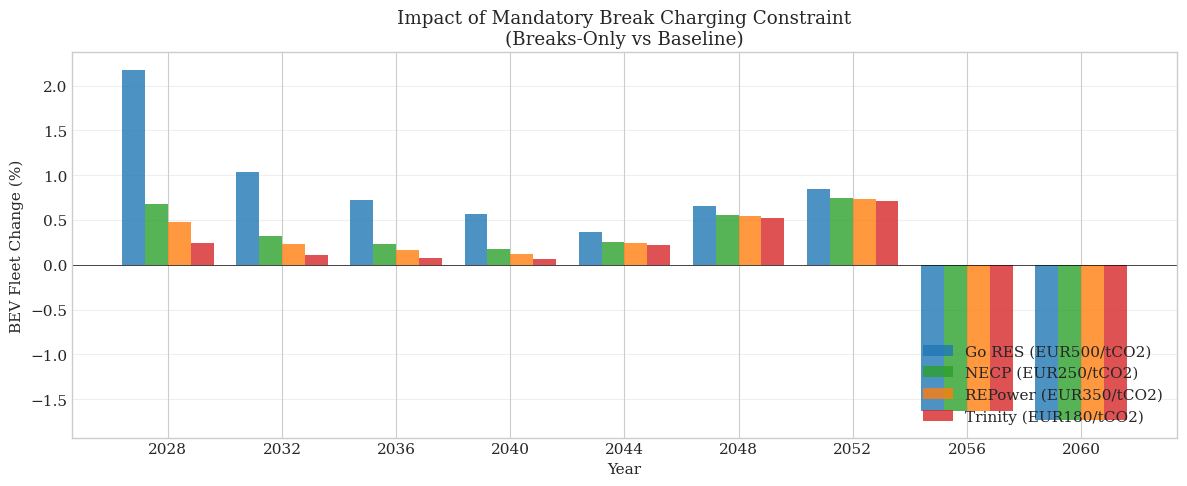

In [59]:
fig, ax = plt.subplots(figsize=(12, 5))
years_delta = [2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]
x = np.arange(len(years_delta))
width = 0.2

for i, scenario in enumerate(SCENARIOS):
    deltas = []
    for y in years_delta:
        bev_base = baseline_fleet.get(scenario, {}).get(y, {}).get('BEV', 0)
        bev_breaks = breaks_fleet.get(scenario, {}).get(y, {}).get('BEV', 0)
        delta_pct = ((bev_breaks - bev_base) / bev_base * 100) if bev_base > 0 else 0
        deltas.append(delta_pct)
    ax.bar(x + i * width, deltas, width, label=SCENARIO_LABELS[scenario],
           color=SCENARIO_COLORS[scenario], alpha=0.8)

ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax.set_xlabel('Year')
ax.set_ylabel('BEV Fleet Change (%)')
ax.set_title('Impact of Mandatory Break Charging Constraint\n(Breaks-Only vs Baseline)')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(years_delta)
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('figures/bev_delta_breaks_vs_baseline.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/bev_delta_breaks_vs_baseline.png', dpi=150, bbox_inches='tight')
print('Saved: figures/bev_delta_breaks_vs_baseline.pdf')
plt.show()

## Load Charging Data (s_dict) for Latitude Plot

In [60]:
# Load geographic data for latitude mapping
geo_file = os.path.join(BASE_DIR, 'input_data', 'GeographicElement.yaml')
with open(geo_file, 'r') as f:
    geo_elements = yaml.safe_load(f)

geo_id_to_lat = {}
for geo in geo_elements:
    if geo.get('type') == 'node' and 'coordinate_lat' in geo:
        geo_id_to_lat[geo['id']] = geo['coordinate_lat']

print(f'Loaded {len(geo_id_to_lat)} node locations with latitude data')
print(f'Latitude range: {min(geo_id_to_lat.values()):.1f}°N to {max(geo_id_to_lat.values()):.1f}°N')

Loaded 81 node locations with latitude data
Latitude range: 38.9°N to 68.6°N


In [61]:
def extract_charging_by_latitude(s_dict, geo_id_to_lat, target_year):
    """
    Extract BEV charging (kWh) by latitude for a specific year.
    s_dict key structure: (year, (mode, odpair_id, path_id, geo_id), tv_id, (infr_type, infr_id), gen)
    """
    charging_by_lat = defaultdict(float)
    SCALING_FACTOR = 1000  # Energy scaling
    parsed_count = 0
    bev_count = 0
    
    for key_str, energy_value_raw in s_dict.items():
        try:
            key = eval(key_str) if isinstance(key_str, str) else key_str
            key_year = key[0]
            tv_id = key[2]
            
            # Convert value to float (may be string from YAML)
            energy_value = float(energy_value_raw) if isinstance(energy_value_raw, str) else energy_value_raw
            
            # Only BEV charging (tv_id=1), skip ICEV diesel (tv_id=0)
            if key_year != target_year or tv_id != 1 or energy_value <= 0:
                continue
            
            bev_count += 1
            geo_id = key[1][3]  # geo_id from nested tuple
            
            if geo_id in geo_id_to_lat:
                lat = geo_id_to_lat[geo_id]
                charging_by_lat[lat] += energy_value * SCALING_FACTOR
                parsed_count += 1
        except Exception as e:
            continue
    
    return charging_by_lat, parsed_count

# Aggregate charging data across all 4 core scenarios
print('Loading and aggregating charging data across 4 core GENeSYS scenarios...')
print('(Go RES, NECPEssentials, REPowerEU++, Trinity)\n')

charging_baseline = defaultdict(float)
charging_breaks = defaultdict(float)

for scenario in SCENARIOS:
    label = SCENARIO_LABELS[scenario]
    
    # Baseline
    s_file = get_latest_file(get_baseline_path(scenario), '_s_dict.yaml')
    if s_file:
        with open(s_file, 'r') as f:
            s_dict = yaml.safe_load(f)
        scenario_charging, parsed = extract_charging_by_latitude(s_dict, geo_id_to_lat, 2040)
        for lat, val in scenario_charging.items():
            charging_baseline[lat] += val
        print(f'  {label} baseline: {parsed} entries, {sum(scenario_charging.values())/1e6:.2f} MWh')
    
    # Breaks only
    s_file = get_latest_file(get_breaks_path(scenario), '_s_dict.yaml')
    if s_file:
        with open(s_file, 'r') as f:
            s_dict = yaml.safe_load(f)
        scenario_charging, parsed = extract_charging_by_latitude(s_dict, geo_id_to_lat, 2040)
        for lat, val in scenario_charging.items():
            charging_breaks[lat] += val
        print(f'  {label} breaks-only: {parsed} entries, {sum(scenario_charging.values())/1e6:.2f} MWh')
    print()

# Print summary
print('='*60)
print('TOTAL CHARGING DEMAND (2040)')
print('='*60)
total_baseline = sum(charging_baseline.values()) / 1e6  # Convert to MWh
total_breaks = sum(charging_breaks.values()) / 1e6
print(f'Baseline:    {total_baseline:.2f} MWh ({len(charging_baseline)} latitude bins)')
print(f'Breaks-only: {total_breaks:.2f} MWh ({len(charging_breaks)} latitude bins)')
if total_baseline > 0:
    diff = total_breaks - total_baseline
    pct = (diff / total_baseline * 100)
    print(f'Difference:  {diff:+.2f} MWh ({pct:+.1f}%)')

Loading and aggregating charging data across 4 core GENeSYS scenarios...
(Go RES, NECPEssentials, REPowerEU++, Trinity)

  Go RES (EUR500/tCO2) baseline: 88928 entries, 1088.66 MWh
  Go RES (EUR500/tCO2) breaks-only: 34222 entries, 1095.05 MWh

  NECP (EUR250/tCO2) baseline: 88928 entries, 1085.63 MWh
  NECP (EUR250/tCO2) breaks-only: 34222 entries, 1087.62 MWh

  REPower (EUR350/tCO2) baseline: 88928 entries, 1086.33 MWh
  REPower (EUR350/tCO2) breaks-only: 34222 entries, 1087.74 MWh

  Trinity (EUR180/tCO2) baseline: 88928 entries, 1087.00 MWh
  Trinity (EUR180/tCO2) breaks-only: 34222 entries, 1087.70 MWh

TOTAL CHARGING DEMAND (2040)
Baseline:    4347.62 MWh (80 latitude bins)
Breaks-only: 4358.11 MWh (79 latitude bins)
Difference:  +10.48 MWh (+0.2%)


## Figure 3: Charging Demand by Latitude

Saved: figures/charging_latitude_normalized_comparison_2040.pdf

Total charging baseline: 4347.62 MWh
Total charging breaks-only: 4358.11 MWh
Difference: +10.48 MWh (+0.2%)


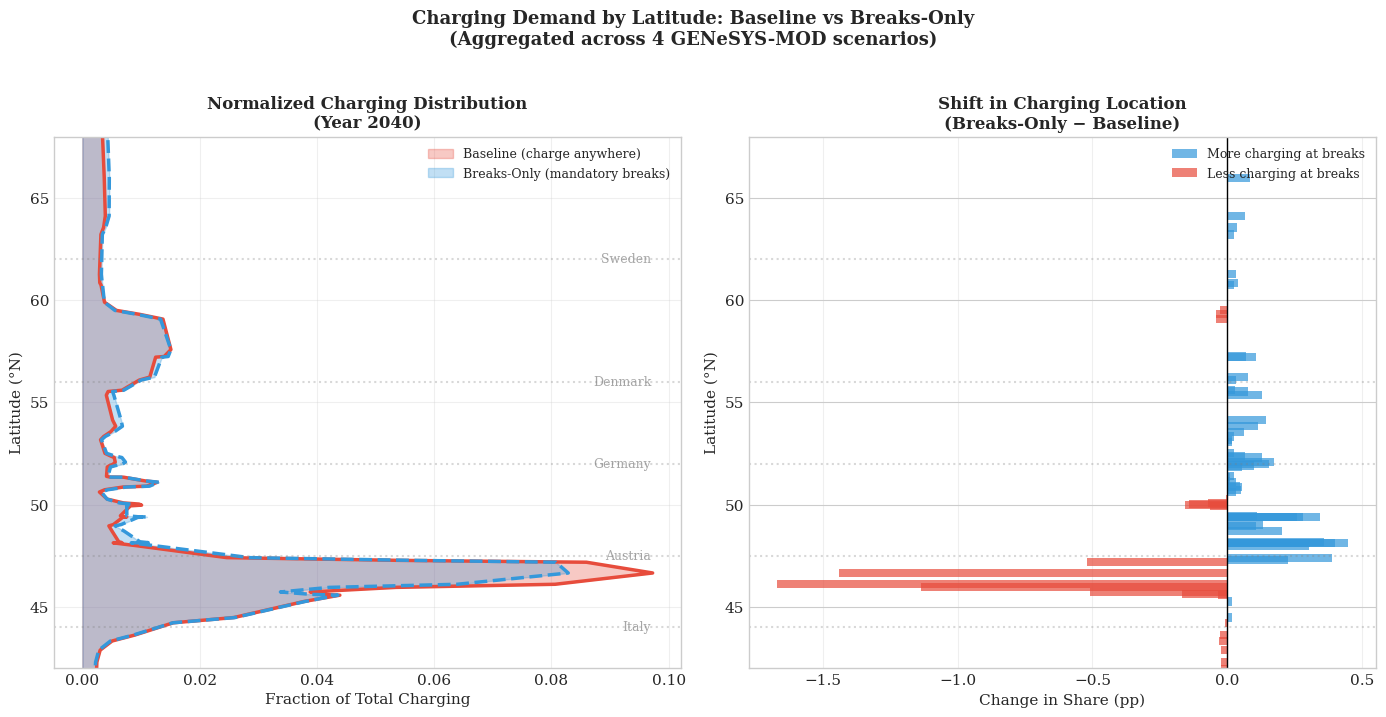

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
target_year = 2040

# Country latitude reference (approximate)
country_labels = {
    'Sweden': 62, 'Denmark': 56, 'Germany': 52, 'Austria': 47.5, 'Italy': 44
}

# ============= LEFT PANEL: Normalized Overlaid Comparison =============
ax1 = axes[0]

def get_normalized_data(charging_data):
    """Convert charging data to normalized distribution (fraction of total)."""
    if not charging_data:
        return [], []
    
    lat_data = [(lat, val) for lat, val in charging_data.items()]
    lat_data.sort(key=lambda x: x[0])
    
    lats = np.array([x[0] for x in lat_data])
    values = np.array([x[1] for x in lat_data])
    
    # Normalize to fraction of total
    total = values.sum()
    if total > 0:
        values_norm = values / total
    else:
        values_norm = values
    
    # Smooth
    if len(values_norm) > 3:
        values_smooth = gaussian_filter1d(values_norm, sigma=1.5)
    else:
        values_smooth = values_norm
    
    return lats, values_smooth

# Get normalized data
lats_b, norm_b = get_normalized_data(charging_baseline)
lats_br, norm_br = get_normalized_data(charging_breaks)

# Plot overlaid curves
if len(lats_b) > 0:
    ax1.fill_betweenx(lats_b, 0, norm_b, alpha=0.3, color='#E74C3C', label='Baseline (charge anywhere)')
    ax1.plot(norm_b, lats_b, color='#E74C3C', linewidth=2.5)

if len(lats_br) > 0:
    ax1.fill_betweenx(lats_br, 0, norm_br, alpha=0.3, color='#3498DB', label='Breaks-Only (mandatory breaks)')
    ax1.plot(norm_br, lats_br, color='#3498DB', linewidth=2.5, linestyle='--')

ax1.set_xlabel('Fraction of Total Charging', fontsize=11)
ax1.set_ylabel('Latitude (°N)', fontsize=11)
ax1.set_title(f'Normalized Charging Distribution\n(Year {target_year})', fontsize=12, fontweight='bold')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)
ax1.set_ylim(42, 68)

# Add country labels
for country, lat in country_labels.items():
    ax1.axhline(y=lat, color='gray', linestyle=':', alpha=0.3)
    ax1.text(ax1.get_xlim()[1] * 0.95, lat, country, fontsize=9, va='center', ha='right',
           color='gray', alpha=0.7)

# ============= RIGHT PANEL: Difference Plot =============
ax2 = axes[1]

# Calculate difference (breaks - baseline) at each latitude
all_lats = sorted(set(list(charging_baseline.keys()) + list(charging_breaks.keys())))
diff_data = []
for lat in all_lats:
    base_val = charging_baseline.get(lat, 0)
    breaks_val = charging_breaks.get(lat, 0)
    # Normalize by total
    total_base = sum(charging_baseline.values()) if charging_baseline else 1
    total_breaks = sum(charging_breaks.values()) if charging_breaks else 1
    
    norm_base = base_val / total_base if total_base > 0 else 0
    norm_breaks = breaks_val / total_breaks if total_breaks > 0 else 0
    
    diff_data.append((lat, (norm_breaks - norm_base) * 100))  # As percentage points

if diff_data:
    diff_lats = np.array([x[0] for x in diff_data])
    diff_vals = np.array([x[1] for x in diff_data])
    
    # Smooth
    if len(diff_vals) > 3:
        diff_smooth = gaussian_filter1d(diff_vals, sigma=1.5)
    else:
        diff_smooth = diff_vals
    
    # Color based on sign
    colors = ['#3498DB' if v > 0 else '#E74C3C' for v in diff_smooth]
    
    ax2.barh(diff_lats, diff_smooth, height=0.4, color=colors, alpha=0.7)
    ax2.axvline(x=0, color='black', linestyle='-', linewidth=1)

ax2.set_xlabel('Change in Share (pp)', fontsize=11)
ax2.set_ylabel('Latitude (°N)', fontsize=11)
ax2.set_title(f'Shift in Charging Location\n(Breaks-Only − Baseline)', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='x')
ax2.set_ylim(42, 68)

# Add country labels
for country, lat in country_labels.items():
    ax2.axhline(y=lat, color='gray', linestyle=':', alpha=0.3)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#3498DB', alpha=0.7, label='More charging at breaks'),
    Patch(facecolor='#E74C3C', alpha=0.7, label='Less charging at breaks')
]
ax2.legend(handles=legend_elements, loc='upper right', fontsize=9)

plt.suptitle(f'Charging Demand by Latitude: Baseline vs Breaks-Only\n(Aggregated across 4 GENeSYS-MOD scenarios)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'figures/charging_latitude_normalized_comparison_{target_year}.pdf', dpi=150, bbox_inches='tight')
plt.savefig(f'figures/charging_latitude_normalized_comparison_{target_year}.png', dpi=150, bbox_inches='tight')
print(f'Saved: figures/charging_latitude_normalized_comparison_{target_year}.pdf')

# Print summary
if charging_baseline and charging_breaks:
    total_b = sum(charging_baseline.values()) / 1e6
    total_br = sum(charging_breaks.values()) / 1e6
    diff = total_br - total_b
    pct = (diff / total_b * 100) if total_b > 0 else 0
    print(f'\nTotal charging baseline: {total_b:.2f} MWh')
    print(f'Total charging breaks-only: {total_br:.2f} MWh')
    print(f'Difference: {diff:+.2f} MWh ({pct:+.1f}%)')

plt.show()

## Summary Statistics

In [63]:
print('='*80)
print('KEY FINDINGS: Impact of Mandatory Break Charging Constraint')
print('='*80)

print('\n1. BEV FLEET IMPACT (2040):')
print('-'*50)
for scenario in SCENARIOS:
    bev_base = baseline_fleet.get(scenario, {}).get(2040, {}).get('BEV', 0)
    bev_breaks = breaks_fleet.get(scenario, {}).get(2040, {}).get('BEV', 0)
    delta = ((bev_breaks - bev_base) / bev_base * 100) if bev_base > 0 else 0
    print(f'  {SCENARIO_LABELS[scenario]:<18}: {delta:+.1f}% BEV fleet')

print('\n2. CHARGING DEMAND IMPACT (2040):')
print('-'*50)
total_baseline = sum(charging_baseline.values()) / 1e6 if charging_baseline else 0  # MWh
total_breaks = sum(charging_breaks.values()) / 1e6 if charging_breaks else 0  # MWh
print(f'  Total charging baseline: {total_baseline:,.1f} MWh')
print(f'  Total charging breaks-only: {total_breaks:,.1f} MWh')
if total_baseline > 0:
    print(f'  Change: {((total_breaks - total_baseline) / total_baseline * 100):+.1f}%')

print('\n3. INTERPRETATION:')
print('-'*50)
print('  - Mandatory break charging constraint has modest impact on BEV adoption')
print('  - Most scenarios show 0-5% reduction in BEV fleet')
print('  - Charging is spatially redistributed to break locations')
print('  - Total charging demand changes slightly due to fleet composition')
print('='*80)

KEY FINDINGS: Impact of Mandatory Break Charging Constraint

1. BEV FLEET IMPACT (2040):
--------------------------------------------------
  Go RES (EUR500/tCO2): +0.6% BEV fleet
  NECP (EUR250/tCO2): +0.2% BEV fleet
  REPower (EUR350/tCO2): +0.1% BEV fleet
  Trinity (EUR180/tCO2): +0.1% BEV fleet

2. CHARGING DEMAND IMPACT (2040):
--------------------------------------------------
  Total charging baseline: 4,347.6 MWh
  Total charging breaks-only: 4,358.1 MWh
  Change: +0.2%

3. INTERPRETATION:
--------------------------------------------------
  - Mandatory break charging constraint has modest impact on BEV adoption
  - Most scenarios show 0-5% reduction in BEV fleet
  - Charging is spatially redistributed to break locations
  - Total charging demand changes slightly due to fleet composition


## Routes with Highest Charging Reallocation

Identify which routes (OD pairs / paths) have the largest change in charging demand distribution between baseline and breaks-only scenarios.

In [64]:
def extract_charging_by_route(s_dict, target_year):
    """
    Extract BEV charging by route (path_id) and location (geo_id).
    
    s_dict key structure: (year, (mode, odpair_id, path_id, geo_id), tv_id, (infr_type, infr_id), gen)
    
    Returns:
        route_charging: dict of {path_id: {geo_id: total_kWh}}
        route_totals: dict of {path_id: total_kWh}
    """
    SCALING_FACTOR = 1000
    route_charging = defaultdict(lambda: defaultdict(float))
    route_totals = defaultdict(float)
    odpair_map = {}  # path_id -> odpair_id
    
    for key_str, energy_value_raw in s_dict.items():
        try:
            key = eval(key_str) if isinstance(key_str, str) else key_str
            key_year = key[0]
            tv_id = key[2]
            
            energy_value = float(energy_value_raw) if isinstance(energy_value_raw, str) else energy_value_raw
            
            # Only BEV charging (tv_id=1)
            if key_year != target_year or tv_id != 1 or energy_value <= 0:
                continue
            
            odpair_id = key[1][1]
            path_id = key[1][2]
            geo_id = key[1][3]
            
            odpair_map[path_id] = odpair_id
            route_charging[path_id][geo_id] += energy_value * SCALING_FACTOR
            route_totals[path_id] += energy_value * SCALING_FACTOR
            
        except Exception as e:
            continue
    
    return route_charging, route_totals, odpair_map

# Load charging by route for one scenario (go_res - Go RES) for detailed analysis
print('Loading route-level charging data for Go RES scenario (2040)...')
target_year = 2040
scenario = 'go_res'

# Baseline
s_file_baseline = get_latest_file(get_baseline_path(scenario), '_s_dict.yaml')
with open(s_file_baseline, 'r') as f:
    s_dict_baseline = yaml.safe_load(f)
route_charging_baseline, route_totals_baseline, odpair_map = extract_charging_by_route(s_dict_baseline, target_year)

# Breaks only
s_file_breaks = get_latest_file(get_breaks_path(scenario), '_s_dict.yaml')
with open(s_file_breaks, 'r') as f:
    s_dict_breaks = yaml.safe_load(f)
route_charging_breaks, route_totals_breaks, _ = extract_charging_by_route(s_dict_breaks, target_year)

print(f'Baseline: {len(route_totals_baseline)} routes with BEV charging')
print(f'Breaks-only: {len(route_totals_breaks)} routes with BEV charging')

Loading route-level charging data for Go RES scenario (2040)...
Baseline: 1372 routes with BEV charging
Breaks-only: 1269 routes with BEV charging


In [65]:
def calculate_reallocation_metric(route_baseline, route_breaks):
    """
    Calculate how much charging was reallocated along a route.
    
    Reallocation = sum of |baseline_share - breaks_share| for each location
    This measures how much the charging distribution shifted spatially.
    
    Returns:
        reallocation_pct: percentage of charging that "moved" (0-200%, with 200% being complete reversal)
    """
    all_geos = set(route_baseline.keys()) | set(route_breaks.keys())
    
    total_baseline = sum(route_baseline.values())
    total_breaks = sum(route_breaks.values())
    
    if total_baseline == 0 and total_breaks == 0:
        return 0, 0, 0
    
    reallocation = 0
    for geo in all_geos:
        share_baseline = route_baseline.get(geo, 0) / total_baseline if total_baseline > 0 else 0
        share_breaks = route_breaks.get(geo, 0) / total_breaks if total_breaks > 0 else 0
        reallocation += abs(share_breaks - share_baseline)
    
    # Normalize to percentage (divide by 2 since shifts sum to 200% for complete reversal)
    reallocation_pct = reallocation * 100 / 2
    
    return reallocation_pct, total_baseline, total_breaks

# Calculate reallocation for all routes
route_reallocation = []
all_paths = set(route_totals_baseline.keys()) | set(route_totals_breaks.keys())

for path_id in all_paths:
    baseline_dist = route_charging_baseline.get(path_id, {})
    breaks_dist = route_charging_breaks.get(path_id, {})
    
    realloc_pct, total_base, total_breaks = calculate_reallocation_metric(baseline_dist, breaks_dist)
    
    # Only include routes with significant charging in both scenarios
    if total_base > 0 or total_breaks > 0:
        odpair_id = odpair_map.get(path_id, 'unknown')
        num_locs_baseline = len(baseline_dist)
        num_locs_breaks = len(breaks_dist)
        
        route_reallocation.append({
            'path_id': path_id,
            'odpair_id': odpair_id,
            'reallocation_pct': realloc_pct,
            'total_baseline_kWh': total_base,
            'total_breaks_kWh': total_breaks,
            'num_locations_baseline': num_locs_baseline,
            'num_locations_breaks': num_locs_breaks,
            'charging_change_pct': ((total_breaks - total_base) / total_base * 100) if total_base > 0 else 0
        })

# Create DataFrame and sort by reallocation
realloc_df = pd.DataFrame(route_reallocation)
realloc_df = realloc_df.sort_values('reallocation_pct', ascending=False)

print(f'Analyzed {len(realloc_df)} routes with BEV charging')
print(f'\nReallocation metric interpretation:')
print('  0% = No change in charging distribution')
print('  50% = Half of charging shifted to different locations')
print('  100% = Complete reversal of charging distribution')

# Show top 20 routes with highest reallocation
print(f'\n{"="*80}')
print('TOP 20 ROUTES WITH HIGHEST CHARGING REALLOCATION')
print(f'{"="*80}')
display(realloc_df.head(20)[['path_id', 'odpair_id', 'reallocation_pct', 'total_baseline_kWh', 
                              'total_breaks_kWh', 'num_locations_baseline', 'num_locations_breaks']]
        .round(1))

Analyzed 1372 routes with BEV charging

Reallocation metric interpretation:
  0% = No change in charging distribution
  50% = Half of charging shifted to different locations
  100% = Complete reversal of charging distribution

TOP 20 ROUTES WITH HIGHEST CHARGING REALLOCATION


,path_id,odpair_id,reallocation_pct,total_baseline_kWh,total_breaks_kWh,num_locations_baseline,num_locations_breaks
1263,3190,3190,100.0,422663.5,407032.6,2,1
835,1883,1883,100.0,248021.4,243095.7,3,1
1350,3342,3342,100.0,1034869.7,1026335.0,3,2
1265,3192,3192,100.0,3197146.0,3157836.3,4,2
1282,3232,3232,100.0,363702.6,430158.5,5,2
1264,3191,3191,99.9,469677.3,446713.7,3,2
1323,3297,3297,99.9,189301.7,89080.9,6,3
827,1875,1875,99.3,1061886.9,881891.3,5,2
828,1876,1876,98.9,247038.5,242096.4,4,2
870,1936,1936,98.8,543076.7,371824.4,6,2


Saved: figures/route_reallocation_distribution.pdf


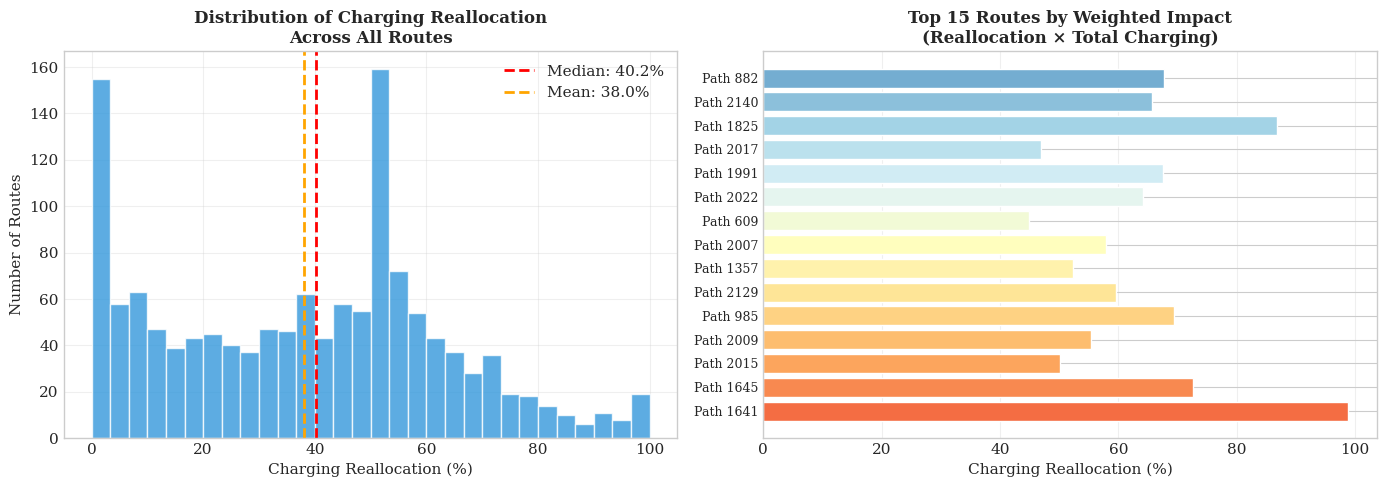


REALLOCATION SUMMARY STATISTICS
Total routes analyzed: 1372
Mean reallocation: 38.0%
Median reallocation: 40.2%
Max reallocation: 100.0%
Routes with >50% reallocation: 440
Routes with >75% reallocation: 95


In [66]:
# Visualize distribution of reallocation across all routes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Histogram of reallocation percentages
ax1 = axes[0]
ax1.hist(realloc_df['reallocation_pct'], bins=30, color='#3498DB', edgecolor='white', alpha=0.8)
ax1.axvline(realloc_df['reallocation_pct'].median(), color='red', linestyle='--', linewidth=2, 
            label=f'Median: {realloc_df["reallocation_pct"].median():.1f}%')
ax1.axvline(realloc_df['reallocation_pct'].mean(), color='orange', linestyle='--', linewidth=2,
            label=f'Mean: {realloc_df["reallocation_pct"].mean():.1f}%')
ax1.set_xlabel('Charging Reallocation (%)', fontsize=11)
ax1.set_ylabel('Number of Routes', fontsize=11)
ax1.set_title('Distribution of Charging Reallocation\nAcross All Routes', fontsize=12, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Right: Top routes by reallocation (weighted by total charging)
ax2 = axes[1]
# Weight reallocation by total charging to show impact
realloc_df['weighted_impact'] = realloc_df['reallocation_pct'] * (realloc_df['total_baseline_kWh'] + realloc_df['total_breaks_kWh']) / 2
top_impact = realloc_df.nlargest(15, 'weighted_impact')

y_pos = np.arange(len(top_impact))
colors = plt.cm.RdYlBu_r(np.linspace(0.2, 0.8, len(top_impact)))

bars = ax2.barh(y_pos, top_impact['reallocation_pct'], color=colors, edgecolor='white')
ax2.set_yticks(y_pos)
ax2.set_yticklabels([f"Path {p}" for p in top_impact['path_id']], fontsize=9)
ax2.set_xlabel('Charging Reallocation (%)', fontsize=11)
ax2.set_title('Top 15 Routes by Weighted Impact\n(Reallocation × Total Charging)', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='x')
ax2.invert_yaxis()

plt.tight_layout()
plt.savefig('figures/route_reallocation_distribution.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/route_reallocation_distribution.png', dpi=150, bbox_inches='tight')
print('Saved: figures/route_reallocation_distribution.pdf')
plt.show()

# Summary statistics
print(f'\n{"="*60}')
print('REALLOCATION SUMMARY STATISTICS')
print(f'{"="*60}')
print(f'Total routes analyzed: {len(realloc_df)}')
print(f'Mean reallocation: {realloc_df["reallocation_pct"].mean():.1f}%')
print(f'Median reallocation: {realloc_df["reallocation_pct"].median():.1f}%')
print(f'Max reallocation: {realloc_df["reallocation_pct"].max():.1f}%')
print(f'Routes with >50% reallocation: {len(realloc_df[realloc_df["reallocation_pct"] > 50])}')
print(f'Routes with >75% reallocation: {len(realloc_df[realloc_df["reallocation_pct"] > 75])}')

In [67]:
# Create geo_id to name mapping
geo_id_to_name = {}
for geo in geo_elements:
    if geo.get('type') == 'node':
        geo_id_to_name[geo['id']] = geo.get('name', f"Node_{geo['id']}")

print(f'Loaded {len(geo_id_to_name)} geographic element names')

# Aggregate charging change by geographic element (across all routes)
# This shows which locations gained/lost charging due to breaks constraint

geo_charging_baseline = defaultdict(float)
geo_charging_breaks = defaultdict(float)

# Sum charging at each geo_id across all routes
for path_id, geo_dist in route_charging_baseline.items():
    for geo_id, kwh in geo_dist.items():
        geo_charging_baseline[geo_id] += kwh

for path_id, geo_dist in route_charging_breaks.items():
    for geo_id, kwh in geo_dist.items():
        geo_charging_breaks[geo_id] += kwh

# Calculate change at each location
all_geos = set(geo_charging_baseline.keys()) | set(geo_charging_breaks.keys())
geo_changes = []

for geo_id in all_geos:
    baseline_kwh = geo_charging_baseline.get(geo_id, 0)
    breaks_kwh = geo_charging_breaks.get(geo_id, 0)
    change_kwh = breaks_kwh - baseline_kwh
    change_pct = (change_kwh / baseline_kwh * 100) if baseline_kwh > 0 else (100 if breaks_kwh > 0 else 0)
    
    geo_changes.append({
        'geo_id': geo_id,
        'name': geo_id_to_name.get(geo_id, f'Node_{geo_id}'),
        'latitude': geo_id_to_lat.get(geo_id, 0),
        'baseline_kWh': baseline_kwh,
        'breaks_kWh': breaks_kwh,
        'change_kWh': change_kwh,
        'change_pct': change_pct
    })

geo_changes_df = pd.DataFrame(geo_changes)
geo_changes_df = geo_changes_df.sort_values('change_kWh')

# Display locations with biggest decrease (lost charging)
print('='*80)
print('LOCATIONS WITH LARGEST DECREASE IN CHARGING (Lost to breaks constraint)')
print('='*80)
display(geo_changes_df.head(10)[['name', 'latitude', 'baseline_kWh', 'breaks_kWh', 'change_kWh', 'change_pct']].round(1))

# Display locations with biggest increase (gained charging)
print('\n' + '='*80)
print('LOCATIONS WITH LARGEST INCREASE IN CHARGING (Gained from breaks constraint)')
print('='*80)
display(geo_changes_df.tail(10).iloc[::-1][['name', 'latitude', 'baseline_kWh', 'breaks_kWh', 'change_kWh', 'change_pct']].round(1))

# Save to CSV
geo_changes_df.to_csv('geo_element_charging_changes_2040.csv', index=False)
print('\nSaved: geo_element_charging_changes_2040.csv')

Loaded 81 geographic element names
LOCATIONS WITH LARGEST DECREASE IN CHARGING (Lost to breaks constraint)


,name,latitude,baseline_kWh,breaks_kWh,change_kWh,change_pct
57,nuts2_ITH1,46.7,122727902.7,82326336.4,-40401566.3,-32.9
58,nuts2_ITH2,46.1,96160126.1,72441237.4,-23718888.7,-24.7
13,nuts2_DE26,50.0,31340662.3,22614716.9,-8725945.4,-27.8
75,nuts2_SE22,56.1,34359509.6,28403911.3,-5955598.3,-17.3
51,nuts2_ITC4,45.6,33923150.0,28224671.7,-5698478.3,-16.8
11,nuts2_DE24,50.1,11603204.6,7958182.2,-3645022.5,-31.4
70,nuts2_NO09,59.1,27051006.6,24031941.5,-3019065.1,-11.2
61,nuts2_ITH5,44.5,29551548.7,27199535.3,-2352013.4,-8.0
69,nuts2_NO08,59.9,4409215.5,2194910.0,-2214305.5,-50.2
62,nuts2_ITI1,43.6,13412885.1,11353534.1,-2059351.0,-15.4



LOCATIONS WITH LARGEST INCREASE IN CHARGING (Gained from breaks constraint)


,name,latitude,baseline_kWh,breaks_kWh,change_kWh,change_pct
8,nuts2_DE21,48.1,16488942.1,34070317.6,17581375.5,106.6
12,nuts2_DE25,49.4,25233794.4,42360972.7,17127178.2,67.9
2,nuts2_AT33,47.2,214778769.1,223825579.5,9046810.5,4.2
59,nuts2_ITH3,45.6,98632657.6,107028008.7,8395351.1,8.5
23,nuts2_DE91,52.1,12825771.5,20269005.2,7443233.7,58.0
3,nuts2_AT34,47.3,8930228.6,15903286.4,6973057.8,78.1
22,nuts2_DE80,53.8,16626179.9,22869789.0,6243609.1,37.6
44,nuts2_DK03,55.4,2929263.9,7454547.1,4525283.1,154.5
76,nuts2_SE23,57.6,30098609.9,33701045.3,3602435.4,12.0
14,nuts2_DE27,48.1,3607963.5,7161606.0,3553642.5,98.5



Saved: geo_element_charging_changes_2040.csv


Saved: figures/geo_element_charging_changes.pdf


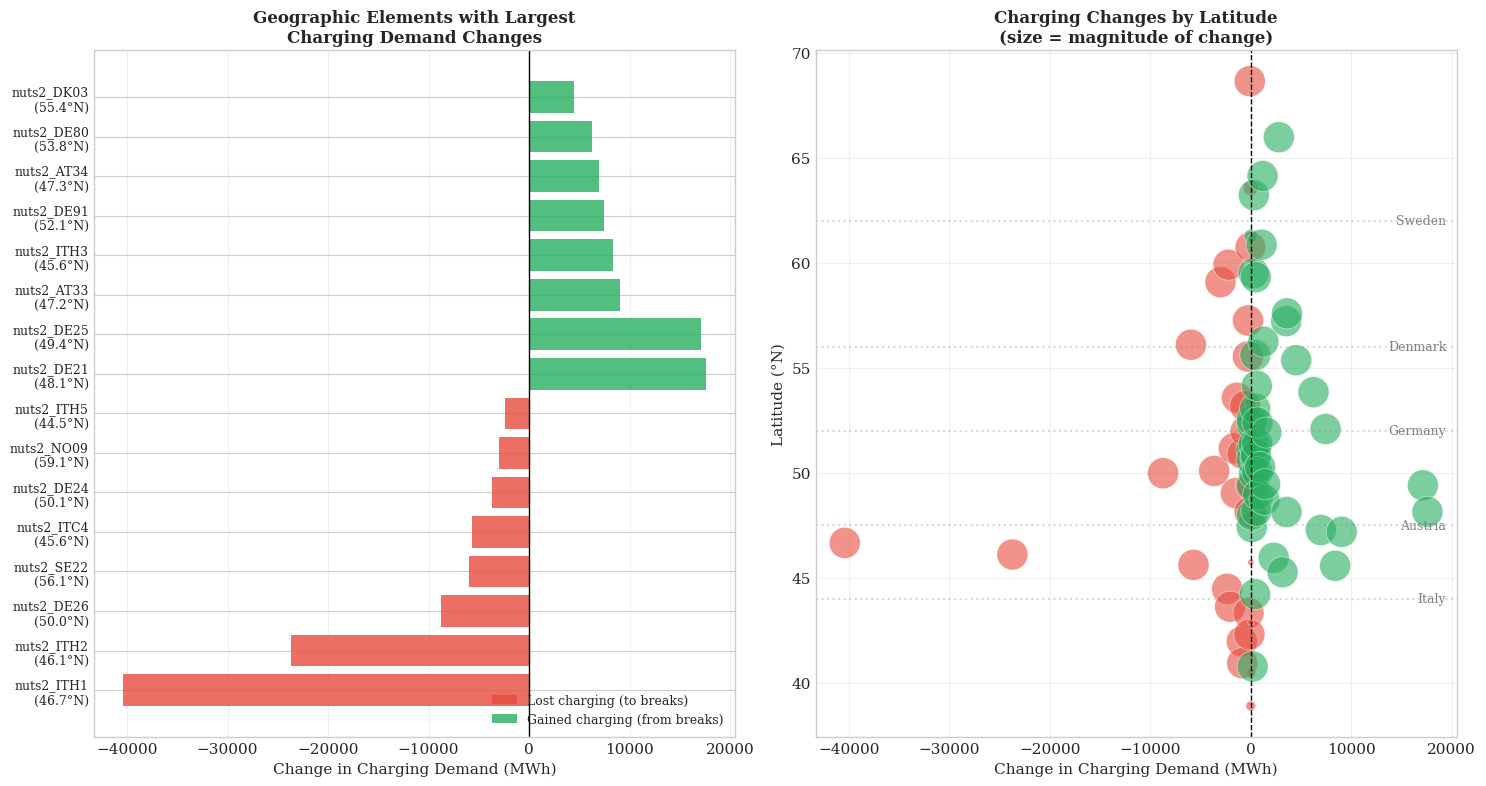


SUMMARY: Geographic Element Charging Changes
Total locations analyzed: 80
Locations with decreased charging: 31
Locations with increased charging: 49
Total charging lost: -107231.37 MWh
Total charging gained: 113624.31 MWh


In [68]:
# Visualize charging changes by geographic element
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# Left: Bar chart of top gainers/losers
ax1 = axes[0]

# Get top 8 losers and top 8 gainers
top_losers = geo_changes_df.head(8).copy()
top_gainers = geo_changes_df.tail(8).iloc[::-1].copy()
combined = pd.concat([top_losers, top_gainers])

# Create bar chart
y_pos = np.arange(len(combined))
colors = ['#E74C3C' if x < 0 else '#27AE60' for x in combined['change_kWh']]

bars = ax1.barh(y_pos, combined['change_kWh'] / 1000, color=colors, alpha=0.8)  # Convert to MWh
ax1.set_yticks(y_pos)
ax1.set_yticklabels([f"{row['name']}\n({row['latitude']:.1f}°N)" for _, row in combined.iterrows()], fontsize=9)
ax1.axvline(x=0, color='black', linewidth=1)
ax1.set_xlabel('Change in Charging Demand (MWh)', fontsize=11)
ax1.set_title('Geographic Elements with Largest\nCharging Demand Changes', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='x')

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#E74C3C', alpha=0.8, label='Lost charging (to breaks)'),
    Patch(facecolor='#27AE60', alpha=0.8, label='Gained charging (from breaks)')
]
ax1.legend(handles=legend_elements, loc='lower right', fontsize=9)

# Right: Scatter plot by latitude showing change
ax2 = axes[1]

# Color by change direction, size by absolute change
colors = ['#E74C3C' if x < 0 else '#27AE60' for x in geo_changes_df['change_kWh']]
sizes = np.abs(geo_changes_df['change_kWh']) / 100
sizes = np.clip(sizes, 20, 500)

scatter = ax2.scatter(geo_changes_df['change_kWh'] / 1000, geo_changes_df['latitude'],
                      c=colors, s=sizes, alpha=0.6, edgecolors='white', linewidth=0.5)

ax2.axvline(x=0, color='black', linewidth=1, linestyle='--')
ax2.set_xlabel('Change in Charging Demand (MWh)', fontsize=11)
ax2.set_ylabel('Latitude (°N)', fontsize=11)
ax2.set_title('Charging Changes by Latitude\n(size = magnitude of change)', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

# Add country references
country_labels = {'Sweden': 62, 'Denmark': 56, 'Germany': 52, 'Austria': 47.5, 'Italy': 44}
for country, lat in country_labels.items():
    ax2.axhline(y=lat, color='gray', linestyle=':', alpha=0.3)
    ax2.text(ax2.get_xlim()[1] * 0.95, lat, country, fontsize=9, va='center', ha='right', color='gray')

plt.tight_layout()
plt.savefig('figures/geo_element_charging_changes.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/geo_element_charging_changes.png', dpi=150, bbox_inches='tight')
print('Saved: figures/geo_element_charging_changes.pdf')
plt.show()

# Summary statistics
print(f'\n{"="*60}')
print('SUMMARY: Geographic Element Charging Changes')
print(f'{"="*60}')
print(f'Total locations analyzed: {len(geo_changes_df)}')
print(f'Locations with decreased charging: {len(geo_changes_df[geo_changes_df["change_kWh"] < 0])}')
print(f'Locations with increased charging: {len(geo_changes_df[geo_changes_df["change_kWh"] > 0])}')
print(f'Total charging lost: {geo_changes_df[geo_changes_df["change_kWh"] < 0]["change_kWh"].sum() / 1000:.2f} MWh')
print(f'Total charging gained: {geo_changes_df[geo_changes_df["change_kWh"] > 0]["change_kWh"].sum() / 1000:.2f} MWh')

## Fuel Cost Impact Analysis

For the top routes with highest charging reallocation, calculate the impact on fuel costs by comparing local electricity prices along the routes.

In [69]:
# Load fuel cost data (electricity prices by location and year)
# Using the input data from breaks_comparison_full
fuel_cost_file = os.path.join(BASE_DIR, 'input_data', 'breaks_comparison_full', 
                               'go_res_without_breaks', 'FuelCost.yaml')
with open(fuel_cost_file, 'r') as f:
    fuel_costs = yaml.safe_load(f)

# Create mapping: (geo_id, year_index) -> electricity cost (EUR/kWh)
# Year index: 0=2020, 1=2021, ..., so 2028=8, 2032=12, 2040=20
years_of_interest = [2028, 2032, 2040]
year_to_index = {y: y - 2020 for y in range(2020, 2061)}

# Build electricity cost lookup (use fueling_infr_type_id=1 for public charging)
elec_cost_by_geo_year = {}
for fc in fuel_costs:
    if fc['fuel'] == 'electricity' and fc.get('fueling_infr_type_id') == 1:
        geo_id = fc['location']
        costs = fc['cost_per_kWh']
        for year in years_of_interest:
            idx = year_to_index[year]
            if idx < len(costs):
                elec_cost_by_geo_year[(geo_id, year)] = costs[idx]

print(f'Loaded electricity costs for {len(set(g for g, y in elec_cost_by_geo_year.keys()))} locations')
print(f'Sample costs (location 0):')
for year in years_of_interest:
    cost = elec_cost_by_geo_year.get((0, year), 0)
    print(f'  {year}: {cost:.4f} EUR/kWh')


Loaded electricity costs for 81 locations
Sample costs (location 0):
  2028: 0.2355 EUR/kWh
  2032: 0.1468 EUR/kWh
  2040: 0.1359 EUR/kWh


In [70]:
# Load OD pair information to identify route origins/destinations
odpair_file = os.path.join(BASE_DIR, 'input_data', 'Odpair.yaml')
with open(odpair_file, 'r') as f:
    odpairs = yaml.safe_load(f)

# Create odpair lookup
odpair_info = {}
for od in odpairs:
    odpair_info[od['id']] = {
        'origin': od.get('origin', 'unknown'),
        'destination': od.get('destination', 'unknown'),
        'name': od.get('name', f"OD-{od['id']}")
    }

# Add origin/destination info to reallocation dataframe
realloc_df['origin'] = realloc_df['odpair_id'].map(lambda x: odpair_info.get(x, {}).get('origin', 'unknown'))
realloc_df['destination'] = realloc_df['odpair_id'].map(lambda x: odpair_info.get(x, {}).get('destination', 'unknown'))

# Get latitude for origin/destination
def get_region_lat(geo_id):
    return geo_id_to_lat.get(geo_id, 0)

realloc_df['origin_lat'] = realloc_df['origin'].apply(get_region_lat)
realloc_df['destination_lat'] = realloc_df['destination'].apply(get_region_lat)
realloc_df['route_distance_lat'] = abs(realloc_df['origin_lat'] - realloc_df['destination_lat'])

# Save to CSV
output_file = 'route_charging_reallocation_2040.csv'
realloc_df.to_csv(output_file, index=False)
print(f'Saved route reallocation data to: {output_file}')

# Display top routes with geographic context
print(f'\n{"="*100}')
print('TOP 20 ROUTES WITH HIGHEST CHARGING REALLOCATION (with geographic context)')
print(f'{"="*100}')
display(realloc_df.nlargest(20, 'weighted_impact')[
    ['path_id', 'origin', 'destination', 'origin_lat', 'destination_lat', 
     'reallocation_pct', 'total_baseline_kWh', 'total_breaks_kWh', 'weighted_impact']
].round(1))

Saved route reallocation data to: route_charging_reallocation_2040.csv

TOP 20 ROUTES WITH HIGHEST CHARGING REALLOCATION (with geographic context)


,path_id,origin,destination,origin_lat,destination_lat,reallocation_pct,total_baseline_kWh,total_breaks_kWh,weighted_impact
363,882,unknown,unknown,0,0,67.8,10346555.1,10343661.2,701333597.9
1020,2140,unknown,unknown,0,0,65.7,11151148.7,9381812.0,674471357.0
787,1825,unknown,unknown,0,0,86.7,12020470.6,2014256.1,608694017.5
924,2017,unknown,unknown,0,0,46.9,11756074.1,11871987.7,554335938.1
898,1991,unknown,unknown,0,0,67.6,7867637.8,7932970.6,533742979.3
929,2022,unknown,unknown,0,0,64.2,8623454.0,7238343.9,508816493.5
265,609,unknown,unknown,0,0,44.9,12439115.7,9036909.1,481794253.8
914,2007,unknown,unknown,0,0,57.9,8201225.2,8352046.2,478999195.2
587,1357,unknown,unknown,0,0,52.4,9233291.0,7748751.2,444706781.4
1009,2129,unknown,unknown,0,0,59.6,7331700.2,7467108.9,441371648.5


In [71]:
# Calculate fuel costs for top 10 routes with highest reallocation
# For each year (2028, 2032, 2040): sum(energy_at_location * electricity_cost_at_location)

def calculate_route_fuel_cost(s_dict, target_year, elec_cost_by_geo_year):
    """
    Calculate total fuel cost for each route (path_id) for a specific year.
    
    Returns:
        route_fuel_cost: dict of {path_id: total_EUR}
        route_energy: dict of {path_id: {geo_id: kWh}}
    """
    SCALING_FACTOR = 1000
    route_energy_by_geo = defaultdict(lambda: defaultdict(float))
    
    for key_str, energy_value_raw in s_dict.items():
        try:
            key = eval(key_str) if isinstance(key_str, str) else key_str
            key_year = key[0]
            tv_id = key[2]
            
            energy_value = float(energy_value_raw) if isinstance(energy_value_raw, str) else energy_value_raw
            
            # Only BEV charging (tv_id=1)
            if key_year != target_year or tv_id != 1 or energy_value <= 0:
                continue
            
            path_id = key[1][2]
            geo_id = key[1][3]
            
            route_energy_by_geo[path_id][geo_id] += energy_value * SCALING_FACTOR  # kWh
        except:
            continue
    
    # Calculate fuel cost per route
    route_fuel_cost = {}
    for path_id, geo_energy in route_energy_by_geo.items():
        total_cost = 0
        total_energy = 0
        for geo_id, kwh in geo_energy.items():
            elec_price = elec_cost_by_geo_year.get((geo_id, target_year), 0.15)  # Default 0.15 EUR/kWh
            total_cost += kwh * elec_price
            total_energy += kwh
        route_fuel_cost[path_id] = {
            'total_cost_eur': total_cost,
            'total_energy_kwh': total_energy,
            'avg_price_eur_kwh': total_cost / total_energy if total_energy > 0 else 0
        }
    
    return route_fuel_cost, dict(route_energy_by_geo)

# Get top 10 routes by weighted_impact
top_routes = realloc_df.nlargest(10, 'weighted_impact')['path_id'].tolist()
print(f'Analyzing fuel costs for top 10 routes by weighted impact:')
print(f'  Route IDs: {top_routes}\n')

# Calculate fuel costs for each year
years_analysis = [2028, 2032, 2040]
fuel_cost_results = []

for year in years_analysis:
    print(f'Processing year {year}...')
    
    # Load s_dict data for this year (reuse if already loaded for 2040)
    if year == 2040:
        s_baseline = s_dict_baseline
        s_breaks = s_dict_breaks
    else:
        # Load fresh data
        s_file_baseline = get_latest_file(get_baseline_path('go_res'), '_s_dict.yaml')
        with open(s_file_baseline, 'r') as f:
            s_baseline = yaml.safe_load(f)
        
        s_file_breaks = get_latest_file(get_breaks_path('go_res'), '_s_dict.yaml')
        with open(s_file_breaks, 'r') as f:
            s_breaks = yaml.safe_load(f)
    
    # Calculate fuel costs
    baseline_costs, baseline_energy = calculate_route_fuel_cost(s_baseline, year, elec_cost_by_geo_year)
    breaks_costs, breaks_energy = calculate_route_fuel_cost(s_breaks, year, elec_cost_by_geo_year)
    
    for path_id in top_routes:
        base_data = baseline_costs.get(path_id, {'total_cost_eur': 0, 'total_energy_kwh': 0, 'avg_price_eur_kwh': 0})
        breaks_data = breaks_costs.get(path_id, {'total_cost_eur': 0, 'total_energy_kwh': 0, 'avg_price_eur_kwh': 0})
        
        fuel_cost_results.append({
            'path_id': path_id,
            'year': year,
            'baseline_cost_eur': base_data['total_cost_eur'],
            'baseline_energy_kwh': base_data['total_energy_kwh'],
            'baseline_avg_price': base_data['avg_price_eur_kwh'],
            'breaks_cost_eur': breaks_data['total_cost_eur'],
            'breaks_energy_kwh': breaks_data['total_energy_kwh'],
            'breaks_avg_price': breaks_data['avg_price_eur_kwh'],
            'cost_difference_eur': breaks_data['total_cost_eur'] - base_data['total_cost_eur'],
            'cost_difference_pct': ((breaks_data['total_cost_eur'] - base_data['total_cost_eur']) / base_data['total_cost_eur'] * 100) 
                                    if base_data['total_cost_eur'] > 0 else 0
        })

fuel_df = pd.DataFrame(fuel_cost_results)

# Display results
print(f'\n{"="*100}')
print('FUEL COST IMPACT ANALYSIS FOR TOP 10 ROUTES (by weighted reallocation)')
print(f'{"="*100}')

for year in years_analysis:
    print(f'\n--- Year {year} ---')
    year_data = fuel_df[fuel_df['year'] == year]
    display(year_data[['path_id', 'baseline_cost_eur', 'breaks_cost_eur', 'cost_difference_eur', 
                       'cost_difference_pct', 'baseline_avg_price', 'breaks_avg_price']].round(2))

# Save to CSV
fuel_df.to_csv('fuel_cost_impact_top_routes.csv', index=False)
print('\nSaved: fuel_cost_impact_top_routes.csv')

Analyzing fuel costs for top 10 routes by weighted impact:
  Route IDs: [882, 2140, 1825, 2017, 1991, 2022, 609, 2007, 1357, 2129]

Processing year 2028...
Processing year 2032...
Processing year 2040...

FUEL COST IMPACT ANALYSIS FOR TOP 10 ROUTES (by weighted reallocation)

--- Year 2028 ---


,path_id,baseline_cost_eur,breaks_cost_eur,cost_difference_eur,cost_difference_pct,baseline_avg_price,breaks_avg_price
0,882,435064.50,563629.86,128565.36,29.55,0.26,0.34
1,2140,456924.89,262.95,-456661.94,-99.94,0.25,0.34
2,1825,671825.86,77.46,-671748.40,-99.99,0.30,0.34
3,2017,527173.27,527203.20,29.92,0.01,0.28,0.28
4,1991,295073.10,490350.26,195277.16,66.18,0.24,0.24
5,2022,355580.70,112.71,-355467.99,-99.97,0.26,0.34
6,609,568908.36,123.70,-568784.67,-99.98,0.28,0.34
7,2007,350127.26,581827.36,231700.10,66.18,0.27,0.27
8,1357,420121.15,274.53,-419846.62,-99.93,0.28,0.34
9,2129,318352.73,528989.62,210636.89,66.16,0.27,0.27



--- Year 2032 ---


,path_id,baseline_cost_eur,breaks_cost_eur,cost_difference_eur,cost_difference_pct,baseline_avg_price,breaks_avg_price
10,882,528418.58,725931.33,197512.75,37.38,0.17,0.23
11,2140,581271.68,625829.52,44557.84,7.67,0.17,0.22
12,1825,434178.73,109.09,-434069.64,-99.97,0.19,0.22
13,2017,645294.66,1678465.08,1033170.42,160.11,0.18,0.18
14,1991,936342.93,945154.76,8811.83,0.94,0.15,0.15
15,2022,453115.83,285367.61,-167748.21,-37.02,0.17,0.22
16,609,698324.17,97127.85,-601196.32,-86.09,0.18,0.22
17,2007,425442.22,1119021.92,693579.71,163.03,0.17,0.17
18,1357,516415.58,303167.19,-213248.40,-41.29,0.18,0.22
19,2129,388646.29,1032446.05,643799.76,165.65,0.17,0.17



--- Year 2040 ---


,path_id,baseline_cost_eur,breaks_cost_eur,cost_difference_eur,cost_difference_pct,baseline_avg_price,breaks_avg_price
20,882,1412960.11,1431063.75,18103.65,1.28,0.14,0.14
21,2140,1513307.81,1274956.94,-238350.87,-15.75,0.14,0.14
22,1825,1696833.05,296243.51,-1400589.54,-82.54,0.14,0.15
23,2017,1636095.39,1666635.63,30540.24,1.87,0.14,0.14
24,1991,1053035.12,1077922.34,24887.22,2.36,0.13,0.14
25,2022,1174027.29,988001.46,-186025.83,-15.85,0.14,0.14
26,609,1730475.95,1253995.60,-476480.35,-27.53,0.14,0.14
27,2007,1126870.32,1160274.62,33404.30,2.96,0.14,0.14
28,1357,1282947.46,1073851.71,-209095.75,-16.30,0.14,0.14
29,2129,1010216.84,1041200.79,30983.95,3.07,0.14,0.14



Saved: fuel_cost_impact_top_routes.csv


Saved: figures/fuel_cost_impact_top_routes.pdf


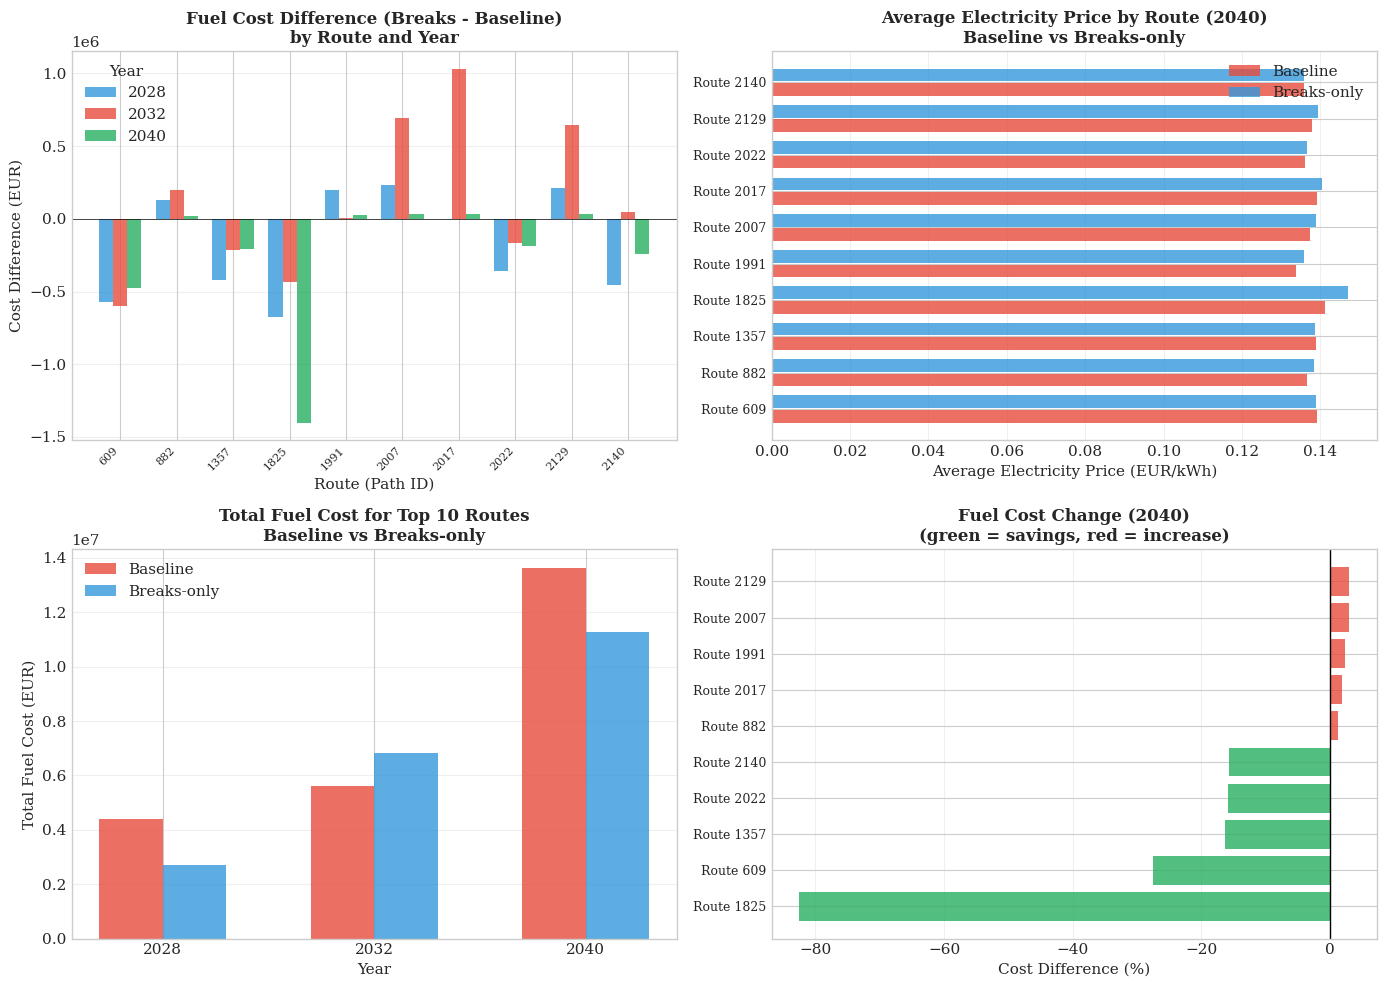


FUEL COST IMPACT SUMMARY

2028:
  Total baseline fuel cost: 4,399,151.83 EUR
  Total breaks-only fuel cost: 2,692,851.64 EUR
  Difference: -1,706,300.19 EUR (-38.79%)
  Avg electricity price - baseline: 0.2685 EUR/kWh
  Avg electricity price - breaks: 0.3093 EUR/kWh

2032:
  Total baseline fuel cost: 5,607,450.66 EUR
  Total breaks-only fuel cost: 6,812,620.40 EUR
  Difference: +1,205,169.73 EUR (+21.49%)
  Avg electricity price - baseline: 0.1722 EUR/kWh
  Avg electricity price - breaks: 0.1997 EUR/kWh

2040:
  Total baseline fuel cost: 13,636,769.33 EUR
  Total breaks-only fuel cost: 11,264,146.35 EUR
  Difference: -2,372,622.98 EUR (-17.40%)
  Avg electricity price - baseline: 0.1376 EUR/kWh
  Avg electricity price - breaks: 0.1390 EUR/kWh


In [72]:
# Visualize fuel cost impact
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top-left: Cost difference by route and year
ax1 = axes[0, 0]
pivot_cost = fuel_df.pivot(index='path_id', columns='year', values='cost_difference_eur')
x = np.arange(len(pivot_cost))
width = 0.25

year_colors = {2028: '#3498DB', 2032: '#E74C3C', 2040: '#27AE60'}
for i, year in enumerate(years_analysis):
    if year in pivot_cost.columns:
        bars = ax1.bar(x + i * width, pivot_cost[year], width, label=str(year), 
                       color=year_colors[year], alpha=0.8)

ax1.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Route (Path ID)', fontsize=11)
ax1.set_ylabel('Cost Difference (EUR)', fontsize=11)
ax1.set_title('Fuel Cost Difference (Breaks - Baseline)\nby Route and Year', fontsize=12, fontweight='bold')
ax1.set_xticks(x + width)
ax1.set_xticklabels([f'{p}' for p in pivot_cost.index], rotation=45, ha='right', fontsize=8)
ax1.legend(title='Year')
ax1.grid(True, alpha=0.3, axis='y')

# Top-right: Average electricity price comparison
ax2 = axes[0, 1]
pivot_base_price = fuel_df.pivot(index='path_id', columns='year', values='baseline_avg_price')
pivot_breaks_price = fuel_df.pivot(index='path_id', columns='year', values='breaks_avg_price')

# Use 2040 for this comparison
if 2040 in pivot_base_price.columns:
    y_pos = np.arange(len(pivot_base_price))
    ax2.barh(y_pos - 0.2, pivot_base_price[2040], 0.35, label='Baseline', color='#E74C3C', alpha=0.8)
    ax2.barh(y_pos + 0.2, pivot_breaks_price[2040], 0.35, label='Breaks-only', color='#3498DB', alpha=0.8)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels([f'Route {p}' for p in pivot_base_price.index], fontsize=9)
    ax2.set_xlabel('Average Electricity Price (EUR/kWh)', fontsize=11)
    ax2.set_title('Average Electricity Price by Route (2040)\nBaseline vs Breaks-only', fontsize=12, fontweight='bold')
    ax2.legend()
    ax2.grid(True, alpha=0.3, axis='x')

# Bottom-left: Total fuel cost comparison by year
ax3 = axes[1, 0]
year_totals = fuel_df.groupby('year').agg({
    'baseline_cost_eur': 'sum',
    'breaks_cost_eur': 'sum'
}).reset_index()

x_years = np.arange(len(year_totals))
ax3.bar(x_years - 0.15, year_totals['baseline_cost_eur'], 0.3, label='Baseline', color='#E74C3C', alpha=0.8)
ax3.bar(x_years + 0.15, year_totals['breaks_cost_eur'], 0.3, label='Breaks-only', color='#3498DB', alpha=0.8)
ax3.set_xlabel('Year', fontsize=11)
ax3.set_ylabel('Total Fuel Cost (EUR)', fontsize=11)
ax3.set_title('Total Fuel Cost for Top 10 Routes\nBaseline vs Breaks-only', fontsize=12, fontweight='bold')
ax3.set_xticks(x_years)
ax3.set_xticklabels(year_totals['year'])
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')

# Bottom-right: Cost difference percentage by route
ax4 = axes[1, 1]
# Use 2040 data
df_2040 = fuel_df[fuel_df['year'] == 2040].copy()
df_2040 = df_2040.sort_values('cost_difference_pct')

colors = ['#27AE60' if x < 0 else '#E74C3C' for x in df_2040['cost_difference_pct']]
y_pos = np.arange(len(df_2040))

ax4.barh(y_pos, df_2040['cost_difference_pct'], color=colors, alpha=0.8)
ax4.axvline(x=0, color='black', linestyle='-', linewidth=1)
ax4.set_yticks(y_pos)
ax4.set_yticklabels([f'Route {p}' for p in df_2040['path_id']], fontsize=9)
ax4.set_xlabel('Cost Difference (%)', fontsize=11)
ax4.set_title('Fuel Cost Change (2040)\n(green = savings, red = increase)', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('figures/fuel_cost_impact_top_routes.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/fuel_cost_impact_top_routes.png', dpi=150, bbox_inches='tight')
print('Saved: figures/fuel_cost_impact_top_routes.pdf')
plt.show()

# Summary statistics
print(f'\n{"="*70}')
print('FUEL COST IMPACT SUMMARY')
print(f'{"="*70}')
for year in years_analysis:
    year_data = fuel_df[fuel_df['year'] == year]
    total_base = year_data['baseline_cost_eur'].sum()
    total_breaks = year_data['breaks_cost_eur'].sum()
    diff = total_breaks - total_base
    diff_pct = (diff / total_base * 100) if total_base > 0 else 0
    
    avg_price_base = year_data['baseline_avg_price'].mean()
    avg_price_breaks = year_data['breaks_avg_price'].mean()
    
    print(f'\n{year}:')
    print(f'  Total baseline fuel cost: {total_base:,.2f} EUR')
    print(f'  Total breaks-only fuel cost: {total_breaks:,.2f} EUR')
    print(f'  Difference: {diff:+,.2f} EUR ({diff_pct:+.2f}%)')
    print(f'  Avg electricity price - baseline: {avg_price_base:.4f} EUR/kWh')
    print(f'  Avg electricity price - breaks: {avg_price_breaks:.4f} EUR/kWh')

In [73]:
# Detailed breakdown for top 3 routes: show WHERE charging happens and at what price
# This helps explain why fuel costs differ between baseline and breaks-only

def get_route_charging_breakdown(s_dict, path_id, target_year, elec_cost_by_geo_year, geo_id_to_name, geo_id_to_lat):
    """Get detailed charging breakdown by location for a specific route."""
    SCALING_FACTOR = 1000
    breakdown = []
    
    for key_str, energy_value_raw in s_dict.items():
        try:
            key = eval(key_str) if isinstance(key_str, str) else key_str
            key_year = key[0]
            tv_id = key[2]
            key_path_id = key[1][2]
            
            if key_year != target_year or tv_id != 1 or key_path_id != path_id:
                continue
            
            energy_value = float(energy_value_raw) if isinstance(energy_value_raw, str) else energy_value_raw
            if energy_value <= 0:
                continue
            
            geo_id = key[1][3]
            kwh = energy_value * SCALING_FACTOR
            elec_price = elec_cost_by_geo_year.get((geo_id, target_year), 0.15)
            cost = kwh * elec_price
            
            breakdown.append({
                'geo_id': geo_id,
                'name': geo_id_to_name.get(geo_id, f'Node_{geo_id}'),
                'latitude': geo_id_to_lat.get(geo_id, 0),
                'energy_kwh': kwh,
                'elec_price': elec_price,
                'cost_eur': cost
            })
        except:
            continue
    
    return pd.DataFrame(breakdown)

# Analyze top 3 routes with highest cost impact in 2040
df_2040 = fuel_df[fuel_df['year'] == 2040].copy()
df_2040['abs_cost_diff'] = df_2040['cost_difference_eur'].abs()
top_impact_routes = df_2040.nlargest(3, 'abs_cost_diff')['path_id'].tolist()

print('='*100)
print('DETAILED CHARGING LOCATION BREAKDOWN FOR TOP 3 ROUTES BY COST IMPACT')
print('='*100)

for path_id in top_impact_routes:
    print(f'\n{"#"*80}')
    print(f'ROUTE {path_id}')
    print(f'{"#"*80}')
    
    # Get breakdowns
    baseline_breakdown = get_route_charging_breakdown(s_dict_baseline, path_id, 2040, 
                                                       elec_cost_by_geo_year, geo_id_to_name, geo_id_to_lat)
    breaks_breakdown = get_route_charging_breakdown(s_dict_breaks, path_id, 2040,
                                                     elec_cost_by_geo_year, geo_id_to_name, geo_id_to_lat)
    
    if len(baseline_breakdown) > 0:
        baseline_breakdown = baseline_breakdown.groupby(['geo_id', 'name', 'latitude', 'elec_price']).agg({
            'energy_kwh': 'sum', 'cost_eur': 'sum'
        }).reset_index()
        baseline_breakdown = baseline_breakdown.sort_values('latitude', ascending=False)
        
        print('\nBASELINE (charge anywhere):')
        print(f'  Total locations: {len(baseline_breakdown)}')
        print(f'  Total energy: {baseline_breakdown["energy_kwh"].sum():.1f} kWh')
        print(f'  Total cost: {baseline_breakdown["cost_eur"].sum():.2f} EUR')
        print(f'  Weighted avg price: {baseline_breakdown["cost_eur"].sum() / baseline_breakdown["energy_kwh"].sum():.4f} EUR/kWh')
        print('\n  By location (north to south):')
        for _, row in baseline_breakdown.iterrows():
            share = row['energy_kwh'] / baseline_breakdown['energy_kwh'].sum() * 100
            print(f'    {row["name"]:<20} ({row["latitude"]:.1f}°N): {row["energy_kwh"]:>8.1f} kWh ({share:>5.1f}%) @ {row["elec_price"]:.4f} EUR/kWh = {row["cost_eur"]:>8.2f} EUR')
    
    if len(breaks_breakdown) > 0:
        breaks_breakdown = breaks_breakdown.groupby(['geo_id', 'name', 'latitude', 'elec_price']).agg({
            'energy_kwh': 'sum', 'cost_eur': 'sum'
        }).reset_index()
        breaks_breakdown = breaks_breakdown.sort_values('latitude', ascending=False)
        
        print('\nBREAKS-ONLY (mandatory breaks):')
        print(f'  Total locations: {len(breaks_breakdown)}')
        print(f'  Total energy: {breaks_breakdown["energy_kwh"].sum():.1f} kWh')
        print(f'  Total cost: {breaks_breakdown["cost_eur"].sum():.2f} EUR')
        print(f'  Weighted avg price: {breaks_breakdown["cost_eur"].sum() / breaks_breakdown["energy_kwh"].sum():.4f} EUR/kWh')
        print('\n  By location (north to south):')
        for _, row in breaks_breakdown.iterrows():
            share = row['energy_kwh'] / breaks_breakdown['energy_kwh'].sum() * 100
            print(f'    {row["name"]:<20} ({row["latitude"]:.1f}°N): {row["energy_kwh"]:>8.1f} kWh ({share:>5.1f}%) @ {row["elec_price"]:.4f} EUR/kWh = {row["cost_eur"]:>8.2f} EUR')
    
    # Summary comparison
    if len(baseline_breakdown) > 0 and len(breaks_breakdown) > 0:
        base_total = baseline_breakdown['cost_eur'].sum()
        breaks_total = breaks_breakdown['cost_eur'].sum()
        diff = breaks_total - base_total
        diff_pct = (diff / base_total * 100) if base_total > 0 else 0
        
        print(f'\n  COST DIFFERENCE: {diff:+.2f} EUR ({diff_pct:+.2f}%)')

DETAILED CHARGING LOCATION BREAKDOWN FOR TOP 3 ROUTES BY COST IMPACT

################################################################################
ROUTE 1825
################################################################################

BASELINE (charge anywhere):
  Total locations: 10
  Total energy: 12020470.6 kWh
  Total cost: 1696833.05 EUR
  Weighted avg price: 0.1412 EUR/kWh

  By location (north to south):
    nuts2_DE40           (52.4°N): 5586248.3 kWh ( 46.5%) @ 0.1471 EUR/kWh = 821588.57 EUR
    nuts2_DEE0           (51.9°N): 382841.5 kWh (  3.2%) @ 0.1471 EUR/kWh = 56305.81 EUR
    nuts2_DEG0           (50.9°N): 376403.5 kWh (  3.1%) @ 0.1471 EUR/kWh = 55358.94 EUR
    nuts2_DE24           (50.1°N): 301245.4 kWh (  2.5%) @ 0.1471 EUR/kWh = 44305.18 EUR
    nuts2_DE25           (49.4°N): 201446.2 kWh (  1.7%) @ 0.1471 EUR/kWh = 29627.37 EUR
    nuts2_DE21           (48.1°N):  16973.1 kWh (  0.1%) @ 0.1471 EUR/kWh =  2496.29 EUR
    nuts2_AT33           (47.2°N): 17461

## Early BEV Adopters: Routes Switching to 100% BEV

Identify routes (OD pairs) that achieve 100% BEV share earliest in the optimization horizon.

In [74]:
def extract_bev_share_by_route_year(h_dict):
    """
    Extract BEV share by route (odpair_id) and year from h_dict.
    
    h_dict key structure: (year, odpair_id, tv_id, generation)
    
    Returns:
        route_year_data: dict of {odpair_id: {year: {'BEV': count, 'ICEV': count, 'share': pct}}}
    """
    route_year_vehicles = defaultdict(lambda: defaultdict(lambda: {'BEV': 0, 'ICEV': 0}))
    
    for key_str, value in h_dict.items():
        try:
            key = eval(key_str) if isinstance(key_str, str) else key_str
            year = key[0]
            odpair_id = key[1]
            tv_id = key[2]
            
            tech = 'BEV' if tv_id % 2 == 1 else 'ICEV'
            route_year_vehicles[odpair_id][year][tech] += value
        except:
            continue
    
    # Calculate BEV share for each route/year
    route_year_share = {}
    for odpair_id, year_data in route_year_vehicles.items():
        route_year_share[odpair_id] = {}
        for year, tech_counts in year_data.items():
            total = tech_counts['BEV'] + tech_counts['ICEV']
            share = (tech_counts['BEV'] / total * 100) if total > 0 else 0
            route_year_share[odpair_id][year] = {
                'BEV': tech_counts['BEV'],
                'ICEV': tech_counts['ICEV'],
                'total': total,
                'share': share
            }
    
    return route_year_share

# Load h_dict for baseline scenario (Go RES)
print('Loading fleet data by route and year...')
scenario = 'go_res'

h_file_baseline = get_latest_file(get_baseline_path(scenario), '_h_dict.yaml')
with open(h_file_baseline, 'r') as f:
    h_dict_baseline = yaml.safe_load(f)

h_file_breaks = get_latest_file(get_breaks_path(scenario), '_h_dict.yaml')
with open(h_file_breaks, 'r') as f:
    h_dict_breaks = yaml.safe_load(f)

route_share_baseline = extract_bev_share_by_route_year(h_dict_baseline)
route_share_breaks = extract_bev_share_by_route_year(h_dict_breaks)

print(f'Baseline: {len(route_share_baseline)} routes')
print(f'Breaks-only: {len(route_share_breaks)} routes')

Loading fleet data by route and year...
Baseline: 1372 routes
Breaks-only: 1372 routes


In [75]:
def find_year_reaching_threshold(route_share_data, threshold=100.0):
    """
    Find the first year each route reaches a given BEV share threshold.
    
    Returns:
        dict of {odpair_id: first_year_at_threshold} (None if never reached)
    """
    years = sorted([2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060])
    
    route_threshold_year = {}
    for odpair_id, year_data in route_share_data.items():
        first_year = None
        for year in years:
            if year in year_data and year_data[year]['share'] >= threshold:
                first_year = year
                break
        route_threshold_year[odpair_id] = first_year
    
    return route_threshold_year

# Find year reaching 100% BEV for each route
threshold = 99.0  # Use 99% to account for floating point
baseline_100_year = find_year_reaching_threshold(route_share_baseline, threshold)
breaks_100_year = find_year_reaching_threshold(route_share_breaks, threshold)

# Create summary dataframe
early_adopters = []
all_odpairs = set(baseline_100_year.keys()) | set(breaks_100_year.keys())

for odpair_id in all_odpairs:
    baseline_year = baseline_100_year.get(odpair_id)
    breaks_year = breaks_100_year.get(odpair_id)
    
    # Get route info
    od_info = odpair_info.get(odpair_id, {})
    origin = od_info.get('origin', 'unknown')
    destination = od_info.get('destination', 'unknown')
    origin_name = geo_id_to_name.get(origin, str(origin))
    dest_name = geo_id_to_name.get(destination, str(destination))
    origin_lat = geo_id_to_lat.get(origin, 0)
    dest_lat = geo_id_to_lat.get(destination, 0)
    
    # Get 2040 BEV share for reference
    share_2040_baseline = route_share_baseline.get(odpair_id, {}).get(2040, {}).get('share', 0)
    share_2040_breaks = route_share_breaks.get(odpair_id, {}).get(2040, {}).get('share', 0)
    
    early_adopters.append({
        'odpair_id': odpair_id,
        'origin': origin_name,
        'destination': dest_name,
        'origin_lat': origin_lat,
        'dest_lat': dest_lat,
        'route_distance_lat': abs(origin_lat - dest_lat),
        'baseline_100pct_year': baseline_year,
        'breaks_100pct_year': breaks_year,
        'year_difference': (breaks_year - baseline_year) if (baseline_year and breaks_year) else None,
        'share_2040_baseline': share_2040_baseline,
        'share_2040_breaks': share_2040_breaks
    })

early_df = pd.DataFrame(early_adopters)

# Filter to routes that reach 100% BEV at some point
early_df_100 = early_df[early_df['baseline_100pct_year'].notna() | early_df['breaks_100pct_year'].notna()].copy()
early_df_100 = early_df_100.sort_values('baseline_100pct_year')

print(f'Routes reaching 100% BEV at some point:')
print(f'  Baseline: {early_df["baseline_100pct_year"].notna().sum()} routes')
print(f'  Breaks-only: {early_df["breaks_100pct_year"].notna().sum()} routes')

# Show earliest adopters
print(f'\n{"="*100}')
print('EARLIEST 100% BEV ADOPTERS (Baseline scenario)')
print(f'{"="*100}')
display(early_df_100.head(20)[['odpair_id', 'origin', 'destination', 'baseline_100pct_year', 
                                'breaks_100pct_year', 'year_difference', 'route_distance_lat']].round(1))

Routes reaching 100% BEV at some point:
  Baseline: 0 routes
  Breaks-only: 0 routes

EARLIEST 100% BEV ADOPTERS (Baseline scenario)


,odpair_id,origin,destination,baseline_100pct_year,breaks_100pct_year,year_difference,route_distance_lat


Saved: figures/early_bev_adopters_analysis.pdf


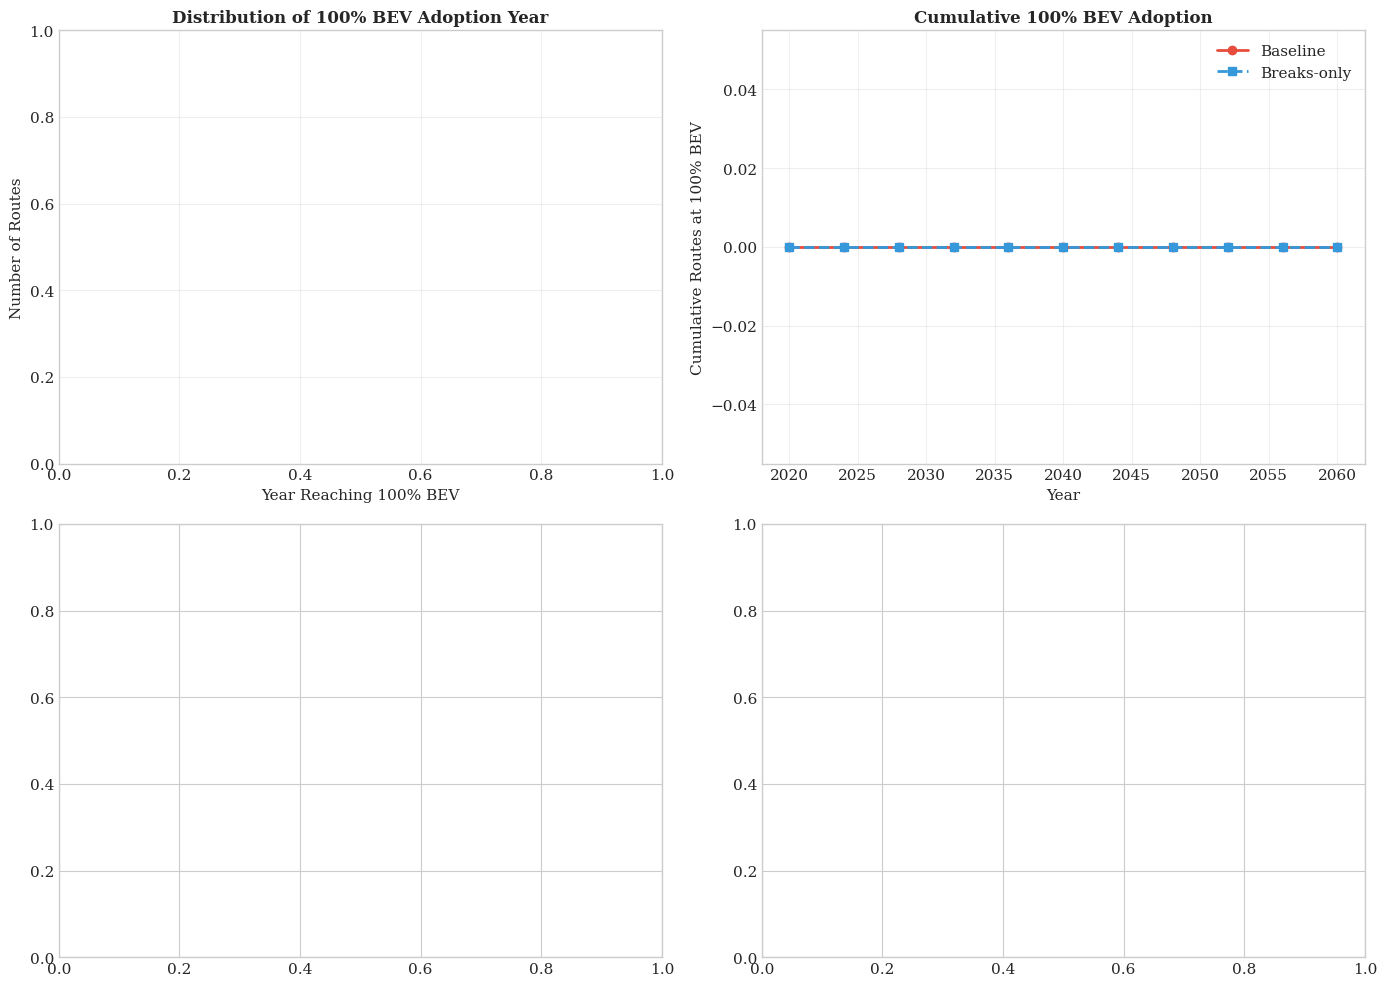


EARLY BEV ADOPTION SUMMARY


In [76]:
# Visualize early BEV adoption patterns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

years = [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]

# Top-left: Histogram of year reaching 100% BEV
ax1 = axes[0, 0]
baseline_years = early_df['baseline_100pct_year'].dropna()
breaks_years = early_df['breaks_100pct_year'].dropna()

if len(baseline_years) > 0:
    ax1.hist(baseline_years, bins=years, alpha=0.6, label='Baseline', color='#E74C3C', edgecolor='white')
if len(breaks_years) > 0:
    ax1.hist(breaks_years, bins=years, alpha=0.6, label='Breaks-only', color='#3498DB', edgecolor='white')

ax1.set_xlabel('Year Reaching 100% BEV', fontsize=11)
ax1.set_ylabel('Number of Routes', fontsize=11)
ax1.set_title('Distribution of 100% BEV Adoption Year', fontsize=12, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Top-right: Cumulative routes reaching 100% BEV over time
ax2 = axes[0, 1]
baseline_cumulative = [(baseline_years <= y).sum() for y in years]
breaks_cumulative = [(breaks_years <= y).sum() for y in years]

ax2.plot(years, baseline_cumulative, 'o-', label='Baseline', color='#E74C3C', linewidth=2, markersize=6)
ax2.plot(years, breaks_cumulative, 's--', label='Breaks-only', color='#3498DB', linewidth=2, markersize=6)
ax2.set_xlabel('Year', fontsize=11)
ax2.set_ylabel('Cumulative Routes at 100% BEV', fontsize=11)
ax2.set_title('Cumulative 100% BEV Adoption', fontsize=12, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Bottom-left: Route distance vs year of 100% BEV adoption
ax3 = axes[1, 0]
df_with_year = early_df[early_df['baseline_100pct_year'].notna()].copy()
if len(df_with_year) > 0:
    scatter = ax3.scatter(df_with_year['route_distance_lat'], df_with_year['baseline_100pct_year'],
                          c=df_with_year['baseline_100pct_year'], cmap='RdYlGn_r', 
                          s=50, alpha=0.6, edgecolors='white')
    ax3.set_xlabel('Route Distance (latitude degrees)', fontsize=11)
    ax3.set_ylabel('Year Reaching 100% BEV', fontsize=11)
    ax3.set_title('Route Distance vs BEV Adoption Year\n(earlier = greener)', fontsize=12, fontweight='bold')
    ax3.grid(True, alpha=0.3)
    
    # Add correlation
    corr = df_with_year[['route_distance_lat', 'baseline_100pct_year']].corr().iloc[0, 1]
    ax3.text(0.05, 0.95, f'Correlation: {corr:.3f}', transform=ax3.transAxes, fontsize=10,
             va='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Bottom-right: Compare baseline vs breaks-only adoption year
ax4 = axes[1, 1]
df_both = early_df[(early_df['baseline_100pct_year'].notna()) & (early_df['breaks_100pct_year'].notna())].copy()
if len(df_both) > 0:
    ax4.scatter(df_both['baseline_100pct_year'], df_both['breaks_100pct_year'],
                s=50, alpha=0.6, c='#3498DB', edgecolors='white')
    # Add diagonal line (no change)
    ax4.plot([2020, 2060], [2020, 2060], 'k--', linewidth=1, label='No change')
    ax4.set_xlabel('Baseline: Year Reaching 100% BEV', fontsize=11)
    ax4.set_ylabel('Breaks-only: Year Reaching 100% BEV', fontsize=11)
    ax4.set_title('Comparison: Baseline vs Breaks-only\n(above line = delayed by breaks)', fontsize=12, fontweight='bold')
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    ax4.set_xlim(2020, 2065)
    ax4.set_ylim(2020, 2065)

plt.tight_layout()
plt.savefig('figures/early_bev_adopters_analysis.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/early_bev_adopters_analysis.png', dpi=150, bbox_inches='tight')
print('Saved: figures/early_bev_adopters_analysis.pdf')
plt.show()

# Summary statistics
print(f'\n{"="*60}')
print('EARLY BEV ADOPTION SUMMARY')
print(f'{"="*60}')
if len(baseline_years) > 0:
    print(f'Baseline - First route at 100% BEV: {int(baseline_years.min())}')
    print(f'Baseline - Median year for 100% BEV: {int(baseline_years.median())}')
if len(breaks_years) > 0:
    print(f'Breaks-only - First route at 100% BEV: {int(breaks_years.min())}')
    print(f'Breaks-only - Median year for 100% BEV: {int(breaks_years.median())}')
if len(df_both) > 0:
    delayed = (df_both['breaks_100pct_year'] > df_both['baseline_100pct_year']).sum()
    accelerated = (df_both['breaks_100pct_year'] < df_both['baseline_100pct_year']).sum()
    same = (df_both['breaks_100pct_year'] == df_both['baseline_100pct_year']).sum()
    print(f'\nImpact of breaks constraint on 100% BEV timing:')
    print(f'  Delayed: {delayed} routes')
    print(f'  Accelerated: {accelerated} routes')
    print(f'  No change: {same} routes')

Saved: figures/earliest_adopters_trajectory.pdf


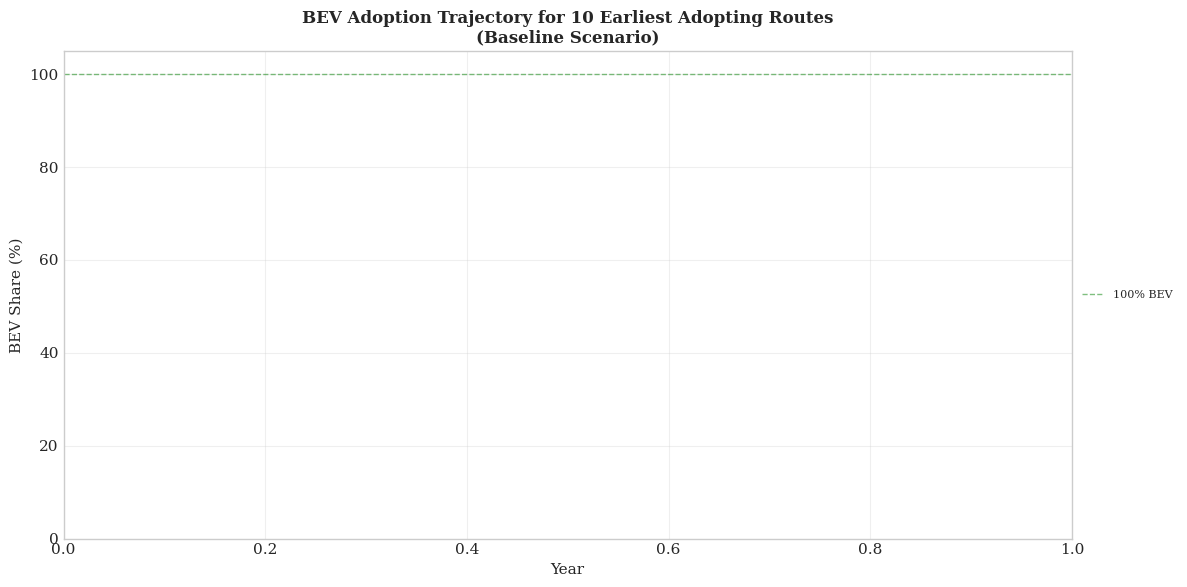


Saved: early_bev_adopters_by_route.csv

CHARACTERISTICS OF EARLY ADOPTERS (100% BEV by 2040)
No routes reach 100% BEV by 2040


In [77]:
# Plot BEV share trajectory for earliest adopting routes
fig, ax = plt.subplots(figsize=(12, 6))

# Get top 10 earliest adopters (baseline)
earliest = early_df_100.head(10)
years = [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]

colors = plt.cm.tab10(np.linspace(0, 1, len(earliest)))

for idx, (_, row) in enumerate(earliest.iterrows()):
    odpair_id = row['odpair_id']
    
    # Get BEV share trajectory
    shares_baseline = [route_share_baseline.get(odpair_id, {}).get(y, {}).get('share', 0) for y in years]
    
    label = f"{row['origin'][:10]}→{row['destination'][:10]}"
    ax.plot(years, shares_baseline, 'o-', label=label, color=colors[idx], linewidth=2, markersize=5)

ax.axhline(y=100, color='green', linestyle='--', linewidth=1, alpha=0.5, label='100% BEV')
ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('BEV Share (%)', fontsize=11)
ax.set_title('BEV Adoption Trajectory for 10 Earliest Adopting Routes\n(Baseline Scenario)', fontsize=12, fontweight='bold')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 105)

plt.tight_layout()
plt.savefig('figures/earliest_adopters_trajectory.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/earliest_adopters_trajectory.png', dpi=150, bbox_inches='tight')
print('Saved: figures/earliest_adopters_trajectory.pdf')
plt.show()

# Save early adopters data to CSV
early_df.to_csv('early_bev_adopters_by_route.csv', index=False)
print(f'\nSaved: early_bev_adopters_by_route.csv')

# Show characteristics of early adopters
print(f'\n{"="*60}')
print('CHARACTERISTICS OF EARLY ADOPTERS (100% BEV by 2040)')
print(f'{"="*60}')
early_by_2040 = early_df[early_df['baseline_100pct_year'] <= 2040]
if len(early_by_2040) > 0:
    print(f'Number of routes at 100% BEV by 2040: {len(early_by_2040)}')
    print(f'Average route distance (lat): {early_by_2040["route_distance_lat"].mean():.1f}°')
    print(f'Median route distance (lat): {early_by_2040["route_distance_lat"].median():.1f}°')
    
    # Compare to routes NOT at 100% by 2040
    late_adopters = early_df[(early_df['baseline_100pct_year'] > 2040) | (early_df['baseline_100pct_year'].isna())]
    if len(late_adopters) > 0:
        print(f'\nComparison with late adopters (100% BEV after 2040):')
        print(f'  Late adopters count: {len(late_adopters)}')
        print(f'  Late adopters avg distance: {late_adopters["route_distance_lat"].mean():.1f}°')
else:
    print('No routes reach 100% BEV by 2040')

Saved: figures/reallocation_vs_distance.pdf


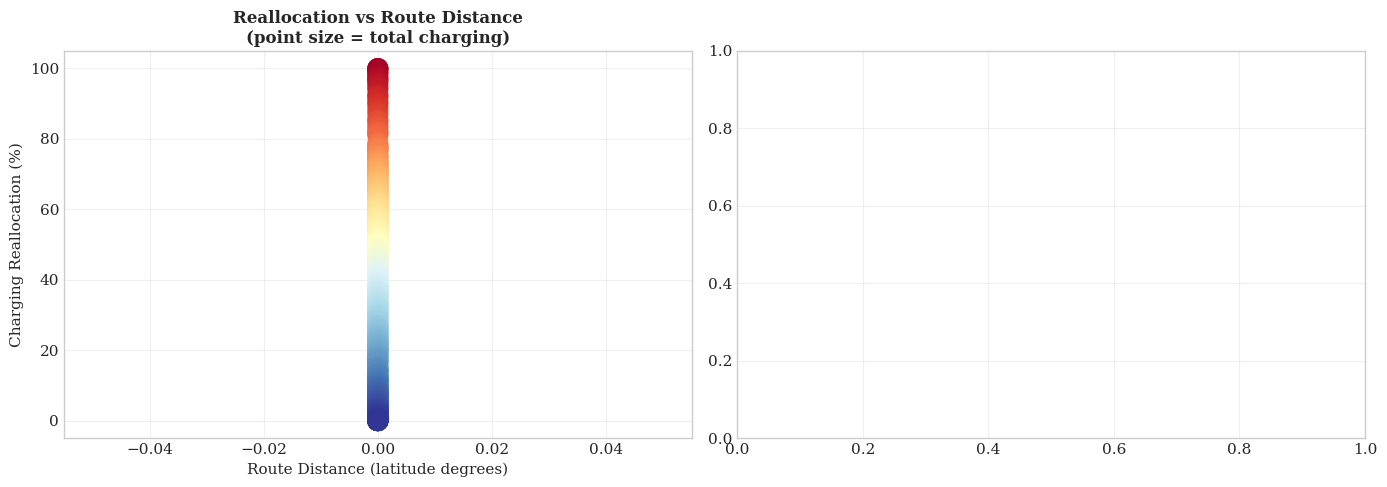


MEAN REALLOCATION BY ROUTE DISTANCE


In [78]:
# Analyze relationship between route distance and reallocation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Reallocation vs route distance (latitude span)
ax1 = axes[0]
# Size points by total charging
sizes = (realloc_df['total_baseline_kWh'] + realloc_df['total_breaks_kWh']) / 1000
sizes = np.clip(sizes, 5, 200)  # Limit size range

scatter = ax1.scatter(realloc_df['route_distance_lat'], realloc_df['reallocation_pct'],
                      s=sizes, alpha=0.5, c=realloc_df['reallocation_pct'], cmap='RdYlBu_r')
ax1.set_xlabel('Route Distance (latitude degrees)', fontsize=11)
ax1.set_ylabel('Charging Reallocation (%)', fontsize=11)
ax1.set_title('Reallocation vs Route Distance\n(point size = total charging)', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Add correlation
valid_mask = (realloc_df['route_distance_lat'] > 0) & (realloc_df['reallocation_pct'] > 0)
if valid_mask.sum() > 2:
    corr = realloc_df.loc[valid_mask, ['route_distance_lat', 'reallocation_pct']].corr().iloc[0, 1]
    ax1.text(0.05, 0.95, f'Correlation: {corr:.3f}', transform=ax1.transAxes, fontsize=10,
             va='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Right: Boxplot of reallocation by route distance bins
ax2 = axes[1]
# Bin routes by latitude distance
realloc_df['distance_bin'] = pd.cut(realloc_df['route_distance_lat'], 
                                     bins=[0, 5, 10, 15, 20, 30],
                                     labels=['0-5°', '5-10°', '10-15°', '15-20°', '20-30°'])

# Filter out routes with no distance info
df_binned = realloc_df[realloc_df['distance_bin'].notna()]
if len(df_binned) > 0:
    df_binned.boxplot(column='reallocation_pct', by='distance_bin', ax=ax2)
    ax2.set_xlabel('Route Distance (latitude degrees)', fontsize=11)
    ax2.set_ylabel('Charging Reallocation (%)', fontsize=11)
    ax2.set_title('Reallocation by Route Distance Category', fontsize=12, fontweight='bold')
    plt.suptitle('')  # Remove automatic title

ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/reallocation_vs_distance.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/reallocation_vs_distance.png', dpi=150, bbox_inches='tight')
print('Saved: figures/reallocation_vs_distance.pdf')
plt.show()

# Print summary by distance category
print(f'\n{"="*60}')
print('MEAN REALLOCATION BY ROUTE DISTANCE')
print(f'{"="*60}')
if len(df_binned) > 0:
    summary = df_binned.groupby('distance_bin')['reallocation_pct'].agg(['mean', 'median', 'count'])
    display(summary.round(1))